# Прогнозирование температуры стали

## Описание проекта

Металлургический комбинат «Стальная птица» планирует уменьшить потребление
электроэнергии на этапе обработки стали. Для имитации технологического процесса
необходимо построить модель, предсказывающую конечную температуру сплава.

Целевой признак — последняя измеренная температура партии.

Основная метрика — MAE. Требуемое значение на тестовой выборке: MAE < 6.8.

## Загрузка и ознакомление с данными

In [1]:
# Импорт библиотек и настройка окружения

from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
    cross_val_score
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 200726
TEST_SIZE = 0.25

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

sns.set_theme(style='whitegrid')

In [2]:
# Загрузка базы данных на платформу

path_to_db = Path('ds-plus-final.db')

if not path_to_db.exists():
    !wget -q https://code.s3.yandex.net/data-scientist/ds-plus-final.db \
        -O ds-plus-final.db

print('Файл базы данных загружен:', path_to_db.exists())

Файл базы данных загружен: True


In [3]:
# Подключение к базе данных
path_to_db = Path('ds-plus-final.db')

if not path_to_db.exists():
    raise FileNotFoundError(f'База данных не найдена: {path_to_db.resolve()}')

connection = sqlite3.connect(path_to_db)

print(f'База данных: {path_to_db.resolve()}')
print(f'Размер файла: {path_to_db.stat().st_size / 1024**2:.2f} МБ')

База данных: /home/jovyan/work/ds-plus-final.db
Размер файла: 3.42 МБ


In [4]:
# Получение списка таблиц
tables_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

table_names = pd.read_sql_query(tables_query, connection)['name'].tolist()

print(f'Количество таблиц: {len(table_names)}')
table_names

Количество таблиц: 11


['contract',
 'data_arc',
 'data_bulk',
 'data_bulk_time',
 'data_gas',
 'data_temp',
 'data_wire',
 'data_wire_time',
 'internet',
 'personal',
 'phone']

В базе данных обнаружено 11 таблиц. Семь таблиц соответствуют условию проекта и содержат сведения о технологическом процессе обработки стали. Таблицы contract, internet, personal и phone не относятся к поставленной задаче, поэтому в дальнейшем анализе не используются.

In [5]:
# Загрузка таблиц
project_tables = [
    'data_arc',
    'data_bulk',
    'data_bulk_time',
    'data_gas',
    'data_temp',
    'data_wire',
    'data_wire_time'
]

missing_tables = set(project_tables) - set(table_names)

if missing_tables:
    raise ValueError(f'Не найдены таблицы: {sorted(missing_tables)}')

data = {
    table_name: pd.read_sql_query(
        f'SELECT * FROM "{table_name}"',
        connection
    )
    for table_name in project_tables
}

connection.close()

In [6]:
# Назначение имен
data_arc = data['data_arc']
data_bulk = data['data_bulk']
data_bulk_time = data['data_bulk_time']
data_gas = data['data_gas']
data_temp = data['data_temp']
data_wire = data['data_wire']
data_wire_time = data['data_wire_time']

In [7]:
# Первичный осмотр данных
overview = []

for table_name, df in data.items():
    overview.append({
        'table': table_name,
        'rows': df.shape[0],
        'columns': df.shape[1],
        'unique_keys': df['key'].nunique() if 'key' in df.columns else np.nan,
        'duplicate_rows': df.duplicated().sum(),
        'missing_values': df.isna().sum().sum()
    })

overview = pd.DataFrame(overview)
overview

,table,rows,columns,unique_keys,duplicate_rows,missing_values
0,data_arc,14876,5,3214,0,0
1,data_bulk,3129,16,3129,0,35776
2,data_bulk_time,3129,16,3129,0,35776
3,data_gas,3239,2,3239,0,0
4,data_temp,18092,3,3216,0,3427
5,data_wire,3081,10,3081,0,23385
6,data_wire_time,3081,10,3081,0,23385


In [8]:
# Структура таблиц и первые строки
for table_name, df in data.items():
    print(f'\n{"=" * 80}')
    print(table_name)
    print(f'Размер: {df.shape}')
    display(df.head())
    display(df.dtypes.rename('dtype').to_frame())


data_arc
Размер: (14876, 5)


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305,0.211
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.766,0.477
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580,0.430
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518,0.380
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867,0.644


,dtype
key,int64
Начало нагрева дугой,object
Конец нагрева дугой,object
Активная мощность,float64
Реактивная мощность,float64



data_bulk
Размер: (3129, 16)


,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,NaN,NaN,NaN,43.000,None,None,None,None,None,None,None,206.0,None,150.0,154.0
1,2,NaN,NaN,NaN,73.000,None,None,None,None,None,None,None,206.0,None,149.0,154.0
2,3,NaN,NaN,NaN,34.000,None,None,None,None,None,None,None,205.0,None,152.0,153.0
3,4,NaN,NaN,NaN,81.000,None,None,None,None,None,None,None,207.0,None,153.0,154.0
4,5,NaN,NaN,NaN,78.000,None,None,None,None,None,None,None,203.0,None,151.0,152.0


,dtype
key,int64
Bulk 1,float64
Bulk 2,float64
Bulk 3,float64
Bulk 4,float64
Bulk 5,object
Bulk 6,object
Bulk 7,object
Bulk 8,object
Bulk 9,object


... (11 outputs left out)

,dtype
key,int64
Wire 1,float64
Wire 2,object
Wire 3,object
Wire 4,object
Wire 5,object
Wire 6,object
Wire 7,object
Wire 8,object
Wire 9,object



data_wire_time
Размер: (3081, 10)


,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,2019-05-03 11:06:19,None,None,None,None,None,None,None,None
1,2,2019-05-03 11:36:50,None,None,None,None,None,None,None,None
2,3,2019-05-03 12:11:46,None,None,None,None,None,None,None,None
3,4,2019-05-03 12:43:22,None,None,None,None,None,None,None,None
4,5,2019-05-03 13:20:44,2019-05-03 13:15:34,None,None,None,None,None,None,None


,dtype
key,int64
Wire 1,object
Wire 2,object
Wire 3,object
Wire 4,object
Wire 5,object
Wire 6,object
Wire 7,object
Wire 8,object
Wire 9,object


In [9]:
# Проверка пропусков по столбцам
for table_name, df in data.items():
    missing = (
        df.isna()
        .sum()
        .rename('missing_count')
        .to_frame()
    )

    missing['missing_share_%'] = (
        missing['missing_count'] / len(df) * 100
    )

    missing = missing[missing['missing_count'] > 0]

    print(f'\n{table_name}')
    if missing.empty:
        print('Пропусков нет')
    else:
        display(missing.sort_values('missing_share_%', ascending=False))


data_arc
Пропусков нет

data_bulk


,missing_count,missing_share_%
Bulk 8,3128,99.968
Bulk 13,3111,99.425
Bulk 9,3110,99.393
Bulk 2,3107,99.297
Bulk 7,3104,99.201
Bulk 5,3052,97.539
Bulk 10,2953,94.375
Bulk 11,2952,94.343
Bulk 1,2877,91.946
Bulk 6,2553,81.592



data_bulk_time


,missing_count,missing_share_%
Bulk 8,3128,99.968
Bulk 13,3111,99.425
Bulk 9,3110,99.393
Bulk 2,3107,99.297
Bulk 7,3104,99.201
Bulk 5,3052,97.539
Bulk 10,2953,94.375
Bulk 11,2952,94.343
Bulk 1,2877,91.946
Bulk 6,2553,81.592



data_gas
Пропусков нет

data_temp


,missing_count,missing_share_%
Температура,3427,18.942



data_wire


,missing_count,missing_share_%
Wire 5,3080,99.968
Wire 7,3070,99.643
Wire 4,3067,99.546
Wire 8,3062,99.383
Wire 9,3052,99.059
Wire 3,3018,97.955
Wire 6,3008,97.631
Wire 2,2002,64.979
Wire 1,26,0.844



data_wire_time


,missing_count,missing_share_%
Wire 5,3080,99.968
Wire 7,3070,99.643
Wire 4,3067,99.546
Wire 8,3062,99.383
Wire 9,3052,99.059
Wire 3,3018,97.955
Wire 6,3008,97.631
Wire 2,2002,64.979
Wire 1,26,0.844


In [10]:
# Исследование столбцов типа object

for table_name, df in data.items():
    object_columns = df.select_dtypes(include='object').columns

    print(f'\n{table_name}')

    for column in object_columns:
        non_null = df[column].dropna()

        value_types = (
            non_null.map(type)
            .value_counts()
            .rename(index=lambda value_type: value_type.__name__)
            .to_dict()
        )

        print(
            f'{column}: '
            f'непустых значений — {len(non_null)}, '
            f'типы — {value_types}'
        )


data_arc
Начало нагрева дугой: непустых значений — 14876, типы — {'str': 14876}
Конец нагрева дугой: непустых значений — 14876, типы — {'str': 14876}

data_bulk
Bulk 5: непустых значений — 77, типы — {'str': 77}
Bulk 6: непустых значений — 576, типы — {'str': 576}
Bulk 7: непустых значений — 25, типы — {'str': 25}
Bulk 8: непустых значений — 1, типы — {'str': 1}
Bulk 9: непустых значений — 19, типы — {'str': 19}
Bulk 10: непустых значений — 176, типы — {'str': 176}
Bulk 11: непустых значений — 177, типы — {'str': 177}
Bulk 12: непустых значений — 2450, типы — {'str': 2450}
Bulk 13: непустых значений — 18, типы — {'str': 18}
Bulk 14: непустых значений — 2806, типы — {'str': 2806}
Bulk 15: непустых значений — 2248, типы — {'str': 2248}

data_bulk_time
Bulk 1: непустых значений — 252, типы — {'str': 252}
Bulk 2: непустых значений — 22, типы — {'str': 22}
Bulk 3: непустых значений — 1298, типы — {'str': 1298}
Bulk 4: непустых значений — 1014, типы — {'str': 1014}
Bulk 5: непустых значений

In [11]:
# Проверка числовых столбцов на некорректные значения

numeric_candidates = {
    'data_bulk': data_bulk.columns.drop('key'),
    'data_temp': ['Температура'],
    'data_wire': data_wire.columns.drop('key')
}

for table_name, columns in numeric_candidates.items():
    df = data[table_name]

    print(f'\n{table_name}')

    for column in columns:
        converted = pd.to_numeric(df[column], errors='coerce')

        conversion_errors = (
            df[column].notna() &
            converted.isna()
        ).sum()

        print(f'{column}: ошибок преобразования — {conversion_errors}')


data_bulk
Bulk 1: ошибок преобразования — 0
Bulk 2: ошибок преобразования — 0
Bulk 3: ошибок преобразования — 0
Bulk 4: ошибок преобразования — 0
Bulk 5: ошибок преобразования — 0
Bulk 6: ошибок преобразования — 0
Bulk 7: ошибок преобразования — 0
Bulk 8: ошибок преобразования — 0
Bulk 9: ошибок преобразования — 0
Bulk 10: ошибок преобразования — 0
Bulk 11: ошибок преобразования — 0
Bulk 12: ошибок преобразования — 0
Bulk 13: ошибок преобразования — 0
Bulk 14: ошибок преобразования — 0
Bulk 15: ошибок преобразования — 0

data_temp
Температура: ошибок преобразования — 0

data_wire
Wire 1: ошибок преобразования — 0
Wire 2: ошибок преобразования — 0
Wire 3: ошибок преобразования — 0
Wire 4: ошибок преобразования — 0
Wire 5: ошибок преобразования — 0
Wire 6: ошибок преобразования — 0
Wire 7: ошибок преобразования — 0
Wire 8: ошибок преобразования — 0
Wire 9: ошибок преобразования — 0


In [12]:
# Преобразование объёмов материалов и температуры в числовой формат

for column in data_bulk.columns.drop('key'):
    data_bulk[column] = pd.to_numeric(
        data_bulk[column],
        errors='coerce'
    )

for column in data_wire.columns.drop('key'):
    data_wire[column] = pd.to_numeric(
        data_wire[column],
        errors='coerce'
    )

data_temp['Температура'] = pd.to_numeric(
    data_temp['Температура'],
    errors='coerce'
)

In [13]:
# Преобразование временных признаков в формат datetime

data_arc['Начало нагрева дугой'] = pd.to_datetime(
    data_arc['Начало нагрева дугой'],
    errors='coerce'
)

data_arc['Конец нагрева дугой'] = pd.to_datetime(
    data_arc['Конец нагрева дугой'],
    errors='coerce'
)

data_temp['Время замера'] = pd.to_datetime(
    data_temp['Время замера'],
    errors='coerce'
)

for column in data_bulk_time.columns.drop('key'):
    data_bulk_time[column] = pd.to_datetime(
        data_bulk_time[column],
        errors='coerce'
    )

for column in data_wire_time.columns.drop('key'):
    data_wire_time[column] = pd.to_datetime(
        data_wire_time[column],
        errors='coerce'
    )

In [14]:
# Проверка типов после преобразования

for table_name, df in data.items():
    print(f'\n{table_name}')
    display(df.dtypes.rename('dtype').to_frame())


data_arc


,dtype
key,int64
Начало нагрева дугой,datetime64[ns]
Конец нагрева дугой,datetime64[ns]
Активная мощность,float64
Реактивная мощность,float64



data_bulk


,dtype
key,int64
Bulk 1,float64
Bulk 2,float64
Bulk 3,float64
Bulk 4,float64
Bulk 5,float64
Bulk 6,float64
Bulk 7,float64
Bulk 8,float64
Bulk 9,float64



data_bulk_time


,dtype
key,int64
Bulk 1,datetime64[ns]
Bulk 2,datetime64[ns]
Bulk 3,datetime64[ns]
Bulk 4,datetime64[ns]
Bulk 5,datetime64[ns]
Bulk 6,datetime64[ns]
Bulk 7,datetime64[ns]
Bulk 8,datetime64[ns]
Bulk 9,datetime64[ns]


... (4 outputs left out)


data_wire


,dtype
key,int64
Wire 1,float64
Wire 2,float64
Wire 3,float64
Wire 4,float64
Wire 5,float64
Wire 6,float64
Wire 7,float64
Wire 8,float64
Wire 9,float64



data_wire_time


,dtype
key,int64
Wire 1,datetime64[ns]
Wire 2,datetime64[ns]
Wire 3,datetime64[ns]
Wire 4,datetime64[ns]
Wire 5,datetime64[ns]
Wire 6,datetime64[ns]
Wire 7,datetime64[ns]
Wire 8,datetime64[ns]
Wire 9,datetime64[ns]


In [15]:
# Проверка совпадения ключей и их порядка в парных таблицах

print(
    'Bulk:',
    data_bulk['key'].equals(data_bulk_time['key'])
)

print(
    'Wire:',
    data_wire['key'].equals(data_wire_time['key'])
)

Bulk: True
Wire: True


In [16]:
# Проверка соответствия объёмов материалов времени их подачи

consistency_results = []

for material in data_bulk.columns.drop('key'):
    amount_exists = data_bulk[material].notna()
    time_exists = data_bulk_time[material].notna()

    consistency_results.append({
        'material': material,
        'amount_without_time': (amount_exists & ~time_exists).sum(),
        'time_without_amount': (~amount_exists & time_exists).sum()
    })

for material in data_wire.columns.drop('key'):
    amount_exists = data_wire[material].notna()
    time_exists = data_wire_time[material].notna()

    consistency_results.append({
        'material': material,
        'amount_without_time': (amount_exists & ~time_exists).sum(),
        'time_without_amount': (~amount_exists & time_exists).sum()
    })

consistency_results = pd.DataFrame(consistency_results)
consistency_results

,material,amount_without_time,time_without_amount
0,Bulk 1,0,0
1,Bulk 2,0,0
2,Bulk 3,0,0
3,Bulk 4,0,0
4,Bulk 5,0,0
5,Bulk 6,0,0
6,Bulk 7,0,0
7,Bulk 8,0,0
8,Bulk 9,0,0
9,Bulk 10,0,0


### Промежуточный вывод

В базе данных обнаружено 11 таблиц, семь из которых относятся к задаче прогнозирования температуры стали. Остальные четыре таблицы не связаны с рассматриваемым технологическим процессом и исключены из дальнейшего анализа.

Первичный осмотр показал, что часть числовых и временных признаков была загружена в формате `object`. Проверка не выявила некорректных значений: все непустые значения целочисленных и вещественных признаков успешно преобразованы в числовой формат, а даты и время — в формат `datetime64[ns]`.

После преобразования типы данных соответствуют содержанию признаков:

- идентификаторы партий представлены целыми числами;
- мощности, температуры и объёмы материалов — числовыми значениями;
- моменты измерений, нагрева и подачи материалов — датой и временем.

В таблицах сыпучих и проволочных материалов пропуск означает, что материал соответствующего типа в партию не добавлялся. Ключи в парных таблицах объёмов и времени подачи материалов полностью совпадают и расположены в одинаковом порядке. Для каждого указанного объёма присутствует время подачи, а для каждого времени — соответствующий объём. Несогласованность между парными таблицами не обнаружена.

В таблице температуры обнаружены отсутствующие значения. Заполнять их статистическими значениями нельзя, поскольку последний действительный замер используется как целевой признак. В дальнейшем будут отобраны только партии, содержащие не менее двух действительных измерений температуры.

Некоторые виды материалов использовались лишь в небольшом числе партий. На текущем этапе они сохранены; решение об их дальнейшем использовании будет принято после объединения данных, исследовательского анализа и оценки полезности признаков.

## Исследовательский анализ и предобработка данных

На этом этапе каждая таблица будет исследована отдельно с учётом её роли
в технологическом процессе. Будут изучены пропуски, аномальные значения,
распределения признаков и количество наблюдений на одну партию. После этого
будут сгенерированы признаки и выполнена агрегация по номеру партии.

### Данные о нагреве электродами — `data_arc`

Таблица содержит интервалы нагрева стали графитовыми электродами, а также
активную и реактивную мощность. Одной партии может соответствовать несколько
запусков нагрева.

In [17]:
# Создание рабочей копии и проверка структуры data_arc

arc = data_arc.copy()

arc_overview = pd.Series({
    'Количество строк': len(arc),
    'Количество столбцов': arc.shape[1],
    'Количество партий': arc['key'].nunique(),
    'Полные дубликаты': arc.duplicated().sum(),
    'Общее количество пропусков': arc.isna().sum().sum()
})

display(arc_overview.to_frame('Значение'))
display(arc.isna().sum().to_frame('Количество пропусков'))

,Значение
Количество строк,14876
Количество столбцов,5
Количество партий,3214
Полные дубликаты,0
Общее количество пропусков,0


,Количество пропусков
key,0
Начало нагрева дугой,0
Конец нагрева дугой,0
Активная мощность,0
Реактивная мощность,0


In [18]:
# Анализ количества запусков нагрева на одну партию

heating_count = arc.groupby('key').size()

display(
    heating_count
    .describe()
    .to_frame('Количество нагревов')
)

display(
    heating_count
    .value_counts()
    .sort_index()
    .rename_axis('Нагревов в партии')
    .to_frame('Количество партий')
)

,Количество нагревов
count,3214.000
mean,4.629
std,1.609
min,1.000
25%,4.000
50%,4.000
75%,6.000
max,16.000


,Количество партий
Нагревов в партии,
1,39
2,174
3,520
4,892
5,759
6,490
7,205
8,84
9,28


In [19]:
# Расчёт длительности каждого запуска нагрева

arc['Длительность нагрева, сек'] = (
    arc['Конец нагрева дугой'] -
    arc['Начало нагрева дугой']
).dt.total_seconds()

display(
    arc['Длительность нагрева, сек']
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame()
)

,"Длительность нагрева, сек"
count,14876.000
mean,171.671
std,98.187
min,11.000
1%,32.000
5%,58.000
25%,107.000
50%,147.000
75%,214.000
95%,360.250


In [20]:
# Проверка данных о нагреве на потенциальные аномалии

arc_quality = pd.Series({
    'Пропущено начало нагрева':
        arc['Начало нагрева дугой'].isna().sum(),

    'Пропущено окончание нагрева':
        arc['Конец нагрева дугой'].isna().sum(),

    'Нулевая длительность':
        arc['Длительность нагрева, сек'].eq(0).sum(),

    'Отрицательная длительность':
        arc['Длительность нагрева, сек'].lt(0).sum(),

    'Неположительная активная мощность':
        arc['Активная мощность'].le(0).sum(),

    'Неположительная реактивная мощность':
        arc['Реактивная мощность'].le(0).sum()
})

display(arc_quality.to_frame('Количество наблюдений'))

,Количество наблюдений
Пропущено начало нагрева,0
Пропущено окончание нагрева,0
Нулевая длительность,0
Отрицательная длительность,0
Неположительная активная мощность,0
Неположительная реактивная мощность,1


In [21]:
# Расчёт описательной статистики признаков нагрева

arc_numeric_columns = [
    'Активная мощность',
    'Реактивная мощность',
    'Длительность нагрева, сек'
]

arc_statistics = (
    arc[arc_numeric_columns]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .T
)

display(arc_statistics)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Активная мощность,14876.000,0.663,0.259,0.223,0.270,0.322,0.467,0.600,0.830,1.180,1.336,1.464
Реактивная мощность,14876.000,0.439,5.873,-715.480,0.194,0.232,0.337,0.442,0.608,0.875,1.032,1.270
"Длительность нагрева, сек",14876.000,171.671,98.187,11.000,32.000,58.000,107.000,147.000,214.000,360.250,508.250,907.000


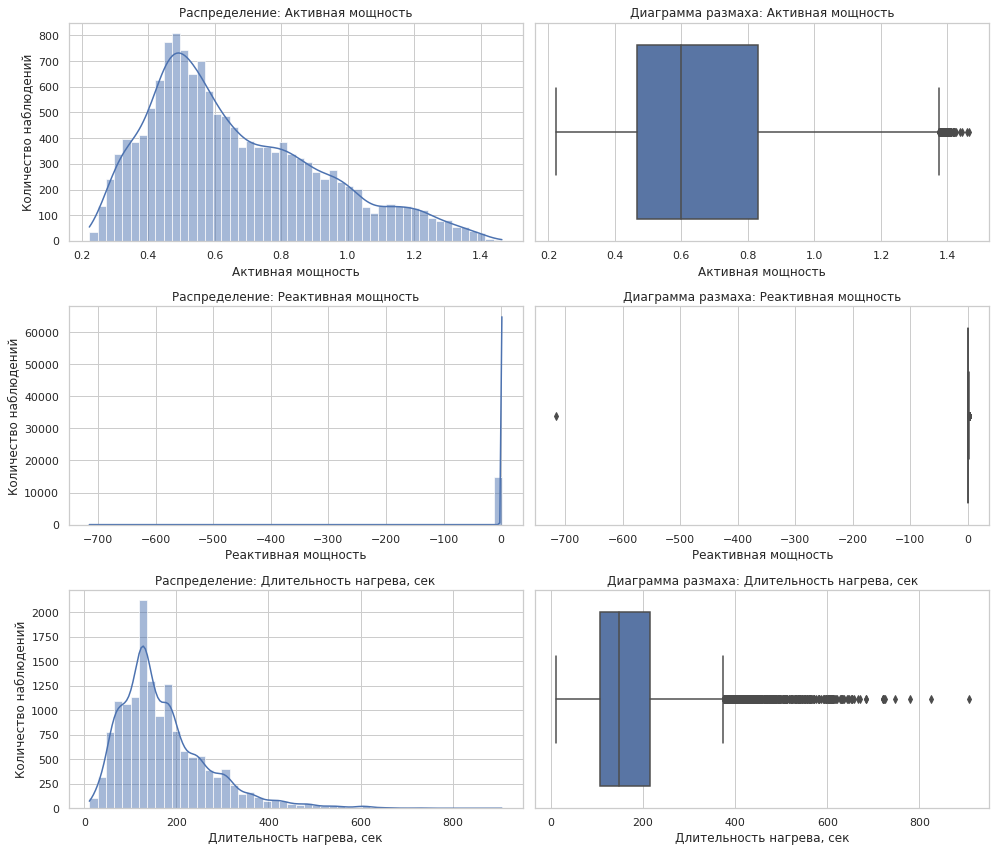

In [22]:
# Визуализация распределений признаков нагрева

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14, 12)
)

for row, column in enumerate(arc_numeric_columns):
    sns.histplot(
        data=arc,
        x=column,
        bins=50,
        kde=True,
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(f'Распределение: {column}')
    axes[row, 0].set_ylabel('Количество наблюдений')

    sns.boxplot(
        data=arc,
        x=column,
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(f'Диаграмма размаха: {column}')

plt.tight_layout()
plt.show()

In [23]:
# Исследование аномального значения реактивной мощности

reactive_anomalies = arc[
    arc['Реактивная мощность'] <= 0
]

display(reactive_anomalies)

anomalous_arc_keys = reactive_anomalies['key'].unique()

display(
    arc[arc['key'].isin(anomalous_arc_keys)]
    .sort_values(['key', 'Начало нагрева дугой'])
)

,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность,"Длительность нагрева, сек"
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705,-715.480,109.000


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность,"Длительность нагрева, сек"
9778,2116,2019-07-28 02:07:12,2019-07-28 02:09:14,0.788,0.694,122.000
9779,2116,2019-07-28 02:13:10,2019-07-28 02:15:25,0.580,0.411,135.000
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705,-715.480,109.000
9781,2116,2019-07-28 02:29:11,2019-07-28 02:30:18,0.564,0.409,67.000


In [24]:
# Исключение партии с аномальной реактивной мощностью

excluded_arc_keys = set(anomalous_arc_keys)

arc = arc[
    ~arc['key'].isin(excluded_arc_keys)
].copy()

print(f'Исключённые партии: {sorted(excluded_arc_keys)}')
print(f'Количество исключённых партий: {len(excluded_arc_keys)}')
print(f'Осталось строк: {len(arc)}')
print(f'Осталось партий: {arc["key"].nunique()}')

Исключённые партии: [2116]
Количество исключённых партий: 1
Осталось строк: 14872
Осталось партий: 3213


,Реактивная мощность
count,14872.000
mean,0.487
std,0.198
min,0.154
1%,0.194
5%,0.232
25%,0.337
50%,0.442
75%,0.608
95%,0.875


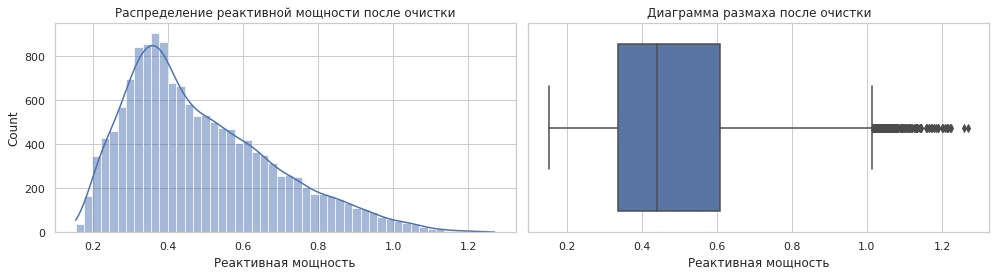

In [25]:
# Проверка распределения реактивной мощности после удаления аномальной партии

display(
    arc['Реактивная мощность']
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .to_frame()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    data=arc,
    x='Реактивная мощность',
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Распределение реактивной мощности после очистки')

sns.boxplot(
    data=arc,
    x='Реактивная мощность',
    ax=axes[1]
)
axes[1].set_title('Диаграмма размаха после очистки')

plt.tight_layout()
plt.show()

In [26]:
# Генерация признаков для каждого запуска нагрева

arc['Полная мощность'] = np.sqrt(
    arc['Активная мощность'] ** 2 +
    arc['Реактивная мощность'] ** 2
)

arc['Соотношение мощностей'] = (
    arc['Активная мощность'] /
    arc['Реактивная мощность']
)

arc['Коэффициент мощности'] = (
    arc['Активная мощность'] /
    arc['Полная мощность']
)

arc['Активная энергия'] = (
    arc['Активная мощность'] *
    arc['Длительность нагрева, сек']
)

arc['Реактивная энергия'] = (
    arc['Реактивная мощность'] *
    arc['Длительность нагрева, сек']
)

arc['Полная энергия'] = (
    arc['Полная мощность'] *
    arc['Длительность нагрева, сек']
)

display(arc.head())

,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность,"Длительность нагрева, сек",Полная мощность,Соотношение мощностей,Коэффициент мощности,Активная энергия,Реактивная энергия,Полная энергия
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305,0.211,228.000,0.371,1.444,0.822,69.570,48.166,84.616
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.766,0.477,185.000,0.902,1.604,0.849,141.647,88.326,166.929
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580,0.430,172.000,0.723,1.348,0.803,99.814,74.039,124.276
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518,0.380,365.000,0.643,1.365,0.807,189.251,138.692,234.631
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867,0.644,148.000,1.080,1.347,0.803,128.336,95.266,159.830


#### Промежуточный вывод по `data_arc`

Таблица содержит 14 876 наблюдений для 3214 партий. Пропуски и полные
дубликаты отсутствуют. На одну партию приходится от 1 до 16 запусков нагрева,
в среднем — 4,63, медианное значение — 4 запуска.

Все интервалы нагрева имеют корректную положительную длительность. Медианная
длительность одного нагрева составляет 147 секунд, максимальная — 907 секунд.
Распределение имеет правый хвост, однако оснований считать продолжительные
нагревы ошибочными не обнаружено.

Активная мощность представлена положительными значениями с плавным
распределением. В реактивной мощности обнаружено одно отрицательное значение
−715,48, которое многократно отличается от диапазона остальных наблюдений.
Поскольку достоверно восстановить измерение невозможно, а удаление отдельной
строки приведёт к неполному описанию партии, принято решение исключить всю
партию с аномальным значением.

До агрегации по номеру партии рассчитаны длительность нагрева, полная мощность,
соотношение активной и реактивной мощности, коэффициент мощности, а также
активная, реактивная и полная энергия каждого запуска нагрева.

In [27]:
# Агрегация признаков нагрева по номеру партии

arc_aggregated = (
    arc.groupby('key')
    .agg(
        Количество_нагревов=(
            'Активная мощность',
            'size'
        ),
        Общая_длительность_нагрева=(
            'Длительность нагрева, сек',
            'sum'
        ),
        Средняя_длительность_нагрева=(
            'Длительность нагрева, сек',
            'mean'
        ),
        Максимальная_длительность_нагрева=(
            'Длительность нагрева, сек',
            'max'
        ),
        Средняя_активная_мощность=(
            'Активная мощность',
            'mean'
        ),
        Средняя_реактивная_мощность=(
            'Реактивная мощность',
            'mean'
        ),
        Средняя_полная_мощность=(
            'Полная мощность',
            'mean'
        ),
        Среднее_соотношение_мощностей=(
            'Соотношение мощностей',
            'mean'
        ),
        Средний_коэффициент_мощности=(
            'Коэффициент мощности',
            'mean'
        ),
        Общая_активная_энергия=(
            'Активная энергия',
            'sum'
        ),
        Общая_реактивная_энергия=(
            'Реактивная энергия',
            'sum'
        ),
        Общая_полная_энергия=(
            'Полная энергия',
            'sum'
        )
    )
    .reset_index()
)

display(arc_aggregated.head())

,key,Количество_нагревов,Общая_длительность_нагрева,Средняя_длительность_нагрева,Максимальная_длительность_нагрева,Средняя_активная_мощность,Средняя_реактивная_мощность,Средняя_полная_мощность,Среднее_соотношение_мощностей,Средний_коэффициент_мощности,Общая_активная_энергия,Общая_реактивная_энергия,Общая_полная_энергия
0,1,5,1098.000,219.600,365.000,0.607,0.429,0.744,1.422,0.817,628.617,444.489,770.282
1,2,4,811.000,202.750,338.000,0.535,0.363,0.647,1.479,0.825,395.282,274.690,481.760
2,3,5,655.000,131.000,280.000,0.813,0.587,1.004,1.396,0.810,581.775,428.039,722.838
3,4,4,741.000,185.250,278.000,0.677,0.514,0.850,1.307,0.794,543.710,413.942,683.456
4,5,4,869.000,217.250,415.000,0.563,0.422,0.704,1.329,0.797,412.180,303.071,512.170


In [28]:
# Проверка агрегированных данных о нагреве

arc_aggregated_overview = pd.Series({
    'Количество строк': len(arc_aggregated),
    'Количество партий': arc_aggregated['key'].nunique(),
    'Дубликаты ключей': arc_aggregated['key'].duplicated().sum(),
    'Количество пропусков': arc_aggregated.isna().sum().sum(),
    'Количество бесконечных значений': (
        np.isinf(
            arc_aggregated.select_dtypes(include='number')
        ).sum().sum()
    )
})

display(arc_aggregated_overview.to_frame('Значение'))

,Значение
Количество строк,3213
Количество партий,3213
Дубликаты ключей,0
Количество пропусков,0
Количество бесконечных значений,0


#### Вывод по `data_arc`

Таблица содержала 14 876 наблюдений для 3214 партий. Пропуски и полные
дубликаты отсутствовали. На одну партию приходилось от 1 до 16 запусков
нагрева, в среднем — 4,63.

Все интервалы нагрева имели корректную положительную длительность. Медианная
длительность одного запуска составила 147 секунд, максимальная — 907 секунд.
Распределение имело правый хвост, однако оснований считать продолжительные
нагревы ошибочными не обнаружено.

В реактивной мощности было обнаружено одно аномальное значение −715,48,
многократно выходившее за диапазон остальных наблюдений. Поскольку достоверно
восстановить измерение невозможно, а удаление только одной строки привело бы
к неполному описанию технологического процесса, соответствующая партия была
исключена полностью.

До агрегации были рассчитаны длительность нагрева, полная мощность,
соотношение активной и реактивной мощности, коэффициент мощности, а также
активная, реактивная и полная энергия каждого запуска. Затем наблюдения были
агрегированы по номеру партии.

Итоговая таблица содержит 3213 строк и 3213 уникальных ключа. Пропуски,
дубликаты ключей и бесконечные значения отсутствуют.

### Данные о сыпучих материалах — `data_bulk`

Таблица содержит объёмы 15 видов сыпучих материалов, добавленных в партии
стали. Одной партии соответствует не более одной строки. Пропуск означает,
что материал соответствующего типа в партию не добавлялся.

In [29]:
# Создание рабочей копии и проверка структуры data_bulk

bulk = data_bulk.copy()
bulk_columns = bulk.columns.drop('key')

bulk_overview = pd.Series({
    'Количество строк': len(bulk),
    'Количество партий': bulk['key'].nunique(),
    'Дубликаты ключей': bulk['key'].duplicated().sum(),
    'Полные дубликаты': bulk.duplicated().sum(),
    'Количество пропусков': bulk[bulk_columns].isna().sum().sum()
})

display(bulk_overview.to_frame('Значение'))

,Значение
Количество строк,3129
Количество партий,3129
Дубликаты ключей,0
Полные дубликаты,0
Количество пропусков,35776


In [30]:
# Анализ частоты использования сыпучих материалов

bulk_usage = pd.DataFrame({
    'Количество партий': bulk[bulk_columns].notna().sum(),
    'Доля партий, %': (
        bulk[bulk_columns].notna().mean() * 100
    )
}).sort_values('Количество партий', ascending=False)

display(bulk_usage)

,Количество партий,"Доля партий, %"
Bulk 14,2806,89.677
Bulk 12,2450,78.300
Bulk 15,2248,71.844
Bulk 3,1298,41.483
Bulk 4,1014,32.407
Bulk 6,576,18.408
Bulk 1,252,8.054
Bulk 11,177,5.657
Bulk 10,176,5.625
Bulk 5,77,2.461


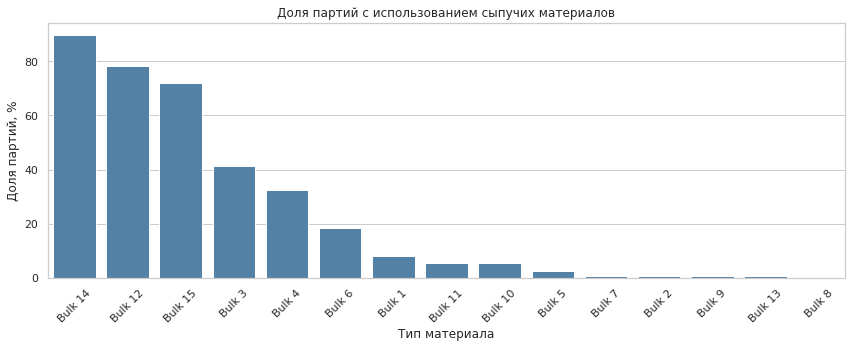

In [31]:
# Визуализация частоты использования сыпучих материалов

plt.figure(figsize=(12, 5))

sns.barplot(
    data=bulk_usage.reset_index(),
    x='index',
    y='Доля партий, %',
    color='steelblue'
)

plt.title('Доля партий с использованием сыпучих материалов')
plt.xlabel('Тип материала')
plt.ylabel('Доля партий, %')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Проверка объёмов сыпучих материалов на потенциальные аномалии

bulk_quality = pd.DataFrame({
    'Непустых значений': bulk[bulk_columns].notna().sum(),
    'Нулевых значений': bulk[bulk_columns].eq(0).sum(),
    'Отрицательных значений': bulk[bulk_columns].lt(0).sum(),
    'Минимум': bulk[bulk_columns].min(),
    'Медиана': bulk[bulk_columns].median(),
    'Максимум': bulk[bulk_columns].max()
})

display(bulk_quality)

,Непустых значений,Нулевых значений,Отрицательных значений,Минимум,Медиана,Максимум
Bulk 1,252,0,0,10.000,31.000,185.000
Bulk 2,22,0,0,228.000,251.500,325.000
Bulk 3,1298,0,0,6.000,97.500,454.000
Bulk 4,1014,0,0,12.000,102.000,281.000
Bulk 5,77,0,0,11.000,86.000,603.000
Bulk 6,576,0,0,17.000,100.000,503.000
Bulk 7,25,0,0,47.000,298.000,772.000
Bulk 8,1,0,0,49.000,49.000,49.000
Bulk 9,19,0,0,63.000,68.000,147.000
Bulk 10,176,0,0,24.000,86.500,159.000


In [33]:
# Проверка партий без сыпучих материалов

bulk_material_count = bulk[bulk_columns].notna().sum(axis=1)

print(
    'Партий без сыпучих материалов:',
    bulk_material_count.eq(0).sum()
)

display(
    bulk_material_count
    .describe()
    .to_frame('Количество типов материалов')
)

Партий без сыпучих материалов: 0


,Количество типов материалов
count,3129.000
mean,3.566
std,1.216
min,1.000
25%,3.000
50%,4.000
75%,4.000
max,7.000


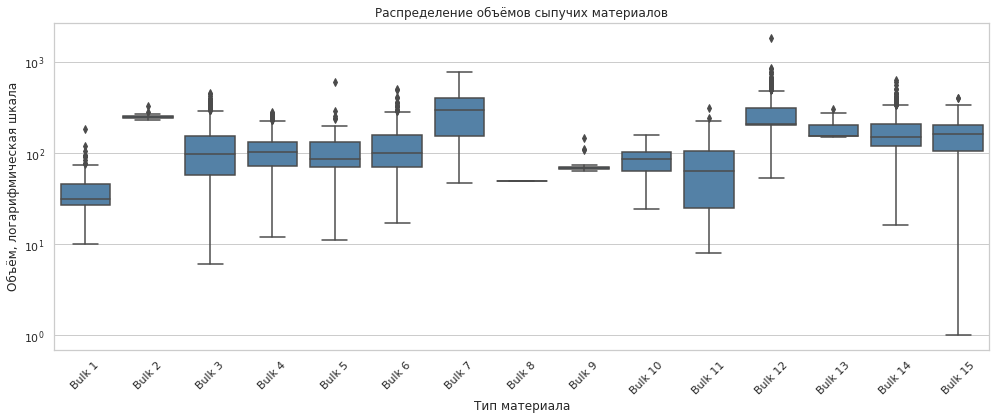

In [34]:
# Подготовка данных для визуализации объёмов материалов

bulk_long = bulk.melt(
    id_vars='key',
    value_vars=bulk_columns,
    var_name='Материал',
    value_name='Объём'
).dropna()

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=bulk_long,
    x='Материал',
    y='Объём',
    color='steelblue'
)

plt.yscale('log')
plt.title('Распределение объёмов сыпучих материалов')
plt.xlabel('Тип материала')
plt.ylabel('Объём, логарифмическая шкала')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
# Анализ верхних значений объёмов сыпучих материалов

bulk_quantiles = pd.DataFrame({
    'Количество наблюдений': bulk[bulk_columns].count(),
    'Медиана': bulk[bulk_columns].median(),
    '95%': bulk[bulk_columns].quantile(0.95),
    '99%': bulk[bulk_columns].quantile(0.99),
    'Максимум': bulk[bulk_columns].max()
})

display(bulk_quantiles)

,Количество наблюдений,Медиана,95%,99%,Максимум
Bulk 1,252,31.000,73.000,98.900,185.000
Bulk 2,22,251.500,281.400,315.970,325.000
Bulk 3,1298,97.500,264.000,343.180,454.000
Bulk 4,1014,102.000,192.000,239.000,281.000
Bulk 5,77,86.000,235.600,367.400,603.000
Bulk 6,576,100.000,261.250,351.750,503.000
Bulk 7,25,298.000,571.400,724.960,772.000
Bulk 8,1,49.000,49.000,49.000,49.000
Bulk 9,19,68.000,114.600,140.520,147.000
Bulk 10,176,86.500,124.250,148.750,159.000


In [36]:
# Заполнение пропусков в объёмах сыпучих материалов

bulk[bulk_columns] = bulk[bulk_columns].fillna(0)

print(
    'Количество пропусков после заполнения:',
    bulk[bulk_columns].isna().sum().sum()
)

Количество пропусков после заполнения: 0


In [37]:
# Генерация признаков на основе сыпучих материалов

bulk['Общий_объём_сыпучих'] = (
    bulk[bulk_columns].sum(axis=1)
)

bulk['Количество_типов_сыпучих'] = (
    bulk[bulk_columns].gt(0).sum(axis=1)
)

display(
    bulk[
        [
            'Общий_объём_сыпучих',
            'Количество_типов_сыпучих'
        ]
    ].describe()
)

,Общий_объём_сыпучих,Количество_типов_сыпучих
count,3129.000,3129.000
mean,595.503,3.566
std,276.558,1.216
min,19.000,1.000
25%,429.000,3.000
50%,591.000,4.000
75%,772.000,4.000
max,3235.000,7.000


In [38]:
# Формирование итоговой таблицы признаков сыпучих материалов

bulk_prepared = bulk.copy()

bulk_prepared_overview = pd.Series({
    'Количество строк': len(bulk_prepared),
    'Количество партий': bulk_prepared['key'].nunique(),
    'Дубликаты ключей': bulk_prepared['key'].duplicated().sum(),
    'Количество пропусков': bulk_prepared.isna().sum().sum()
})

display(bulk_prepared_overview.to_frame('Значение'))

,Значение
Количество строк,3129
Количество партий,3129
Дубликаты ключей,0
Количество пропусков,0


#### Вывод по `data_bulk`

Таблица содержит сведения о сыпучих материалах для 3129 партий. Каждой партии соответствует одна строка. Дубликаты ключей и полные дубликаты отсутствуют.

В исходных данных было обнаружено 35 776 пропусков. Согласно условию задачи, пропуск означает, что материал соответствующего типа в партию не добавлялся, поэтому пропущенные значения были заменены нулями. После обработки пропуски отсутствуют.

Отрицательных и исходных нулевых объёмов не обнаружено. Распределения материалов различаются по масштабу и частоте использования, однако значений, которые можно однозначно признать физически невозможными, не выявлено. Редкие и высокие значения сохранены.

Наиболее часто использовались `Bulk 14`, `Bulk 12` и `Bulk 15`. Некоторые материалы встречались крайне редко: `Bulk 8` использовался только в одной партии. На текущем этапе редкие признаки сохранены; решение об их исключении будет принято после объединения данных и оценки их полезности для модели.

Для каждой партии были рассчитаны два дополнительных признака:

- общий объём добавленных сыпучих материалов;
- количество использованных типов сыпучих материалов.

В среднем в одну партию добавлялось 595,5 единицы сыпучих материалов и использовалось 3,57 их типа. Итоговая подготовленная таблица содержит 3129 строк, уникальный ключ для каждой партии и не содержит пропусков.

### Время подачи сыпучих материалов — `data_bulk_time`

Таблица содержит время подачи каждого типа сыпучего материала. Одной партии
соответствует не более одной строки. Пропуск означает, что материал
соответствующего типа в партию не добавлялся.

In [39]:
# Создание рабочей копии и проверка структуры data_bulk_time

bulk_time = data_bulk_time.copy()
bulk_time_columns = bulk_time.columns.drop('key')

bulk_time_overview = pd.Series({
    'Количество строк': len(bulk_time),
    'Количество партий': bulk_time['key'].nunique(),
    'Дубликаты ключей': bulk_time['key'].duplicated().sum(),
    'Полные дубликаты': bulk_time.duplicated().sum(),
    'Количество пропусков': (
        bulk_time[bulk_time_columns].isna().sum().sum()
    )
})

display(bulk_time_overview.to_frame('Значение'))

,Значение
Количество строк,3129
Количество партий,3129
Дубликаты ключей,0
Полные дубликаты,0
Количество пропусков,35776


In [40]:
# Определение общего временного диапазона подачи материалов

all_bulk_times = (
    bulk_time[bulk_time_columns]
    .stack()
)

bulk_time_range = pd.Series({
    'Самая ранняя подача': all_bulk_times.min(),
    'Самая поздняя подача': all_bulk_times.max(),
    'Количество временных отметок': len(all_bulk_times)
})

display(bulk_time_range.to_frame('Значение'))

,Значение
Самая ранняя подача,2019-05-03 11:10:43
Самая поздняя подача,2019-09-06 17:26:33
Количество временных отметок,11159


In [41]:
# Расчёт интервала между первой и последней подачей сыпучих материалов

bulk_time['Первая_подача_сыпучих'] = (
    bulk_time[bulk_time_columns].min(axis=1)
)

bulk_time['Последняя_подача_сыпучих'] = (
    bulk_time[bulk_time_columns].max(axis=1)
)

bulk_time['Интервал_подачи_сыпучих_сек'] = (
    bulk_time['Последняя_подача_сыпучих'] -
    bulk_time['Первая_подача_сыпучих']
).dt.total_seconds()

display(
    bulk_time['Интервал_подачи_сыпучих_сек']
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .to_frame()
)

,Интервал_подачи_сыпучих_сек
count,3129.000
mean,964.907
std,798.088
min,0.000
1%,0.000
5%,0.000
25%,485.000
50%,877.000
75%,1311.000
95%,2213.000


In [42]:
# Проверка продолжительности подачи материалов на аномальные значения

bulk_time_quality = pd.Series({
    'Отрицательных интервалов':
        bulk_time['Интервал_подачи_сыпучих_сек'].lt(0).sum(),

    'Интервалов больше одного часа':
        bulk_time['Интервал_подачи_сыпучих_сек'].gt(3600).sum(),

    'Интервалов больше суток':
        bulk_time['Интервал_подачи_сыпучих_сек'].gt(86400).sum(),

    'Пропущенных рассчитанных интервалов':
        bulk_time['Интервал_подачи_сыпучих_сек'].isna().sum()
})

display(bulk_time_quality.to_frame('Количество партий'))

,Количество партий
Отрицательных интервалов,0
Интервалов больше одного часа,27
Интервалов больше суток,0
Пропущенных рассчитанных интервалов,0


In [43]:
# Просмотр партий с наиболее длительной подачей сыпучих материалов

bulk_time_longest = (
    bulk_time[
        [
            'key',
            'Первая_подача_сыпучих',
            'Последняя_подача_сыпучих',
            'Интервал_подачи_сыпучих_сек'
        ]
    ]
    .nlargest(
        10,
        'Интервал_подачи_сыпучих_сек'
    )
)

display(bulk_time_longest)

,key,Первая_подача_сыпучих,Последняя_подача_сыпучих,Интервал_подачи_сыпучих_сек
1895,1958,2019-07-21 10:56:00,2019-07-21 14:44:03,13683.000
1819,1881,2019-07-12 10:42:42,2019-07-12 13:55:14,11552.000
1818,1880,2019-07-12 07:45:54,2019-07-12 10:21:30,9336.000
2859,2965,2019-08-28 03:40:56,2019-08-28 05:41:34,7238.000
2470,2562,2019-08-12 19:51:09,2019-08-12 21:42:20,6671.000
3072,3181,2019-09-04 14:20:22,2019-09-04 16:01:08,6046.000
102,115,2019-05-07 17:37:05,2019-05-07 19:13:07,5762.000
2471,2563,2019-08-12 21:48:11,2019-08-12 23:16:11,5280.000
2034,2106,2019-07-27 06:23:07,2019-07-27 07:50:22,5235.000
1459,1513,2019-06-29 07:30:07,2019-06-29 08:54:23,5056.000


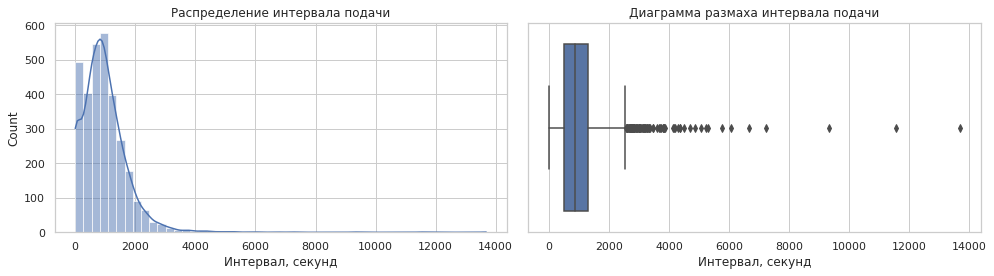

In [44]:
# Визуализация интервала подачи сыпучих материалов

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    data=bulk_time,
    x='Интервал_подачи_сыпучих_сек',
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Распределение интервала подачи')
axes[0].set_xlabel('Интервал, секунд')

sns.boxplot(
    data=bulk_time,
    x='Интервал_подачи_сыпучих_сек',
    ax=axes[1]
)
axes[1].set_title('Диаграмма размаха интервала подачи')
axes[1].set_xlabel('Интервал, секунд')

plt.tight_layout()
plt.show()

In [45]:
# Формирование итоговой таблицы временных признаков сыпучих материалов

bulk_time_prepared = bulk_time[
    [
        'key',
        'Интервал_подачи_сыпучих_сек'
    ]
].copy()

bulk_time_prepared_overview = pd.Series({
    'Количество строк': len(bulk_time_prepared),
    'Количество партий': bulk_time_prepared['key'].nunique(),
    'Дубликаты ключей':
        bulk_time_prepared['key'].duplicated().sum(),
    'Количество пропусков':
        bulk_time_prepared.isna().sum().sum()
})

display(bulk_time_prepared_overview.to_frame('Значение'))

,Значение
Количество строк,3129
Количество партий,3129
Дубликаты ключей,0
Количество пропусков,0


#### Вывод по `data_bulk_time`

Таблица содержит время подачи сыпучих материалов для 3129 партий. Дубликаты
ключей и полные дубликаты отсутствуют. Пропуски соответствуют материалам,
которые не добавлялись в партию, поэтому их заполнение не требуется.

Временные отметки находятся в диапазоне с 3 мая по 6 сентября 2019 года.
Отрицательных интервалов и интервалов продолжительностью более суток не
обнаружено. В 27 партиях промежуток между первой и последней подачей превышал
один час, а максимальное значение составило 13 683 секунды — около 3 часов
48 минут. С учётом предупреждения заказчика об асинхронности временных
показаний эти значения не признаны ошибочными и сохранены.

Абсолютные даты не будут использоваться как признаки, поскольку они не
описывают физические свойства технологического процесса. Для дальнейшего
анализа сохранён относительный признак — интервал между первой и последней
подачей сыпучих материалов.

### Данные о продувке газом — `data_gas`

Таблица содержит объём инертного газа, использованного для продувки и
перемешивания сплава. Одной партии соответствует не более одной строки.

In [46]:
# Создание рабочей копии и проверка структуры data_gas

gas = data_gas.copy()

gas_overview = pd.Series({
    'Количество строк': len(gas),
    'Количество партий': gas['key'].nunique(),
    'Дубликаты ключей': gas['key'].duplicated().sum(),
    'Полные дубликаты': gas.duplicated().sum(),
    'Количество пропусков': gas.isna().sum().sum()
})

display(gas_overview.to_frame('Значение'))

,Значение
Количество строк,3239
Количество партий,3239
Дубликаты ключей,0
Полные дубликаты,0
Количество пропусков,0


In [47]:
# Анализ распределения объёма газа

display(
    gas['Газ 1']
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .to_frame()
)

gas_quality = pd.Series({
    'Нулевых значений': gas['Газ 1'].eq(0).sum(),
    'Отрицательных значений': gas['Газ 1'].lt(0).sum()
})

display(gas_quality.to_frame('Количество партий'))

,Газ 1
count,3239.000
mean,11.002
std,6.220
min,0.008
1%,1.133
5%,3.197
25%,7.043
50%,9.836
75%,13.770
95%,22.626


,Количество партий
Нулевых значений,0
Отрицательных значений,0


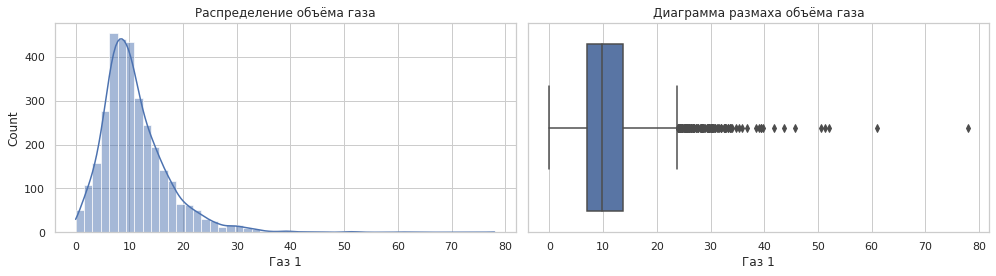

In [48]:
# Визуализация распределения объёма газа

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    data=gas,
    x='Газ 1',
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Распределение объёма газа')

sns.boxplot(
    data=gas,
    x='Газ 1',
    ax=axes[1]
)
axes[1].set_title('Диаграмма размаха объёма газа')

plt.tight_layout()
plt.show()

In [49]:
# Просмотр партий с наибольшим объёмом газа

display(
    gas.nlargest(10, 'Газ 1')
)

,key,Газ 1
319,322,77.995
277,280,60.936
2107,2110,52.142
2567,2570,51.380
116,117,50.581
2105,2108,45.639
1461,1464,43.655
660,663,41.855
525,528,39.729
610,613,39.426


In [50]:
# Формирование итоговой таблицы признаков продувки газом

gas_prepared = gas.copy()

gas_prepared_overview = pd.Series({
    'Количество строк': len(gas_prepared),
    'Количество партий': gas_prepared['key'].nunique(),
    'Дубликаты ключей': gas_prepared['key'].duplicated().sum(),
    'Количество пропусков': gas_prepared.isna().sum().sum()
})

display(gas_prepared_overview.to_frame('Значение'))

,Значение
Количество строк,3239
Количество партий,3239
Дубликаты ключей,0
Количество пропусков,0


#### Вывод по `data_gas`

Таблица содержит сведения об объёме газа для 3239 партий. Каждой партии
соответствует одна строка. Пропуски, дубликаты ключей и полные дубликаты
отсутствуют.

Все значения объёма газа положительны. Медианное значение составляет 9,84,
среднее — 11,00. Распределение имеет правый хвост: 99% наблюдений не превышают
31,56, а максимальное значение равно 78,00.

На диаграмме размаха присутствуют статистические выбросы, однако отрицательных,
нулевых или заведомо невозможных значений не обнаружено. 

Дополнительная обработка таблицы не требуется. Исходный объём газа будет
использован как входной признак модели.

### Измерения температуры — `data_temp`

Таблица содержит результаты измерения температуры стали. Одной партии может
соответствовать несколько замеров. Первый действительный замер будет
использован как входной признак, а последний — как целевой. Промежуточные
температуры использовать нельзя, поскольку это приведёт к утечке целевого
признака.

In [51]:
# Создание рабочей копии и проверка структуры data_temp

temp = data_temp.copy()

temp_overview = pd.Series({
    'Количество строк': len(temp),
    'Количество партий': temp['key'].nunique(),
    'Полные дубликаты': temp.duplicated().sum(),
    'Дубликаты key и времени': (
        temp.duplicated(subset=['key', 'Время замера']).sum()
    ),
    'Пропущено времени замера':
        temp['Время замера'].isna().sum(),
    'Пропущено температуры':
        temp['Температура'].isna().sum()
})

display(temp_overview.to_frame('Значение'))

,Значение
Количество строк,18092
Количество партий,3216
Полные дубликаты,0
Дубликаты key и времени,0
Пропущено времени замера,0
Пропущено температуры,3427


In [52]:
# Анализ количества действительных измерений температуры в каждой партии

valid_measurement_count = (
    temp.groupby('key')['Температура']
    .count()
)

display(
    valid_measurement_count
    .describe()
    .to_frame('Количество действительных замеров')
)

display(
    valid_measurement_count
    .value_counts()
    .sort_index()
    .rename_axis('Замеров в партии')
    .to_frame('Количество партий')
)

,Количество действительных замеров
count,3216.000
mean,4.560
std,2.406
min,1.000
25%,3.000
50%,5.000
75%,6.000
max,17.000


,Количество партий
Замеров в партии,
1,741
2,32
3,136
4,395
5,688
6,580
7,388
8,152
9,66


In [53]:
# Определение партий с достаточным количеством измерений

measurement_eligibility = pd.Series({
    'Всего партий': len(valid_measurement_count),
    'Нет действительных замеров':
        valid_measurement_count.eq(0).sum(),
    'Только один действительный замер':
        valid_measurement_count.eq(1).sum(),
    'Не менее двух действительных замеров':
        valid_measurement_count.ge(2).sum()
})

display(measurement_eligibility.to_frame('Количество партий'))

,Количество партий
Всего партий,3216
Нет действительных замеров,0
Только один действительный замер,741
Не менее двух действительных замеров,2475


In [54]:
# Расчёт описательной статистики температуры

display(
    temp['Температура']
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .to_frame()
)

temperature_quality = pd.Series({
    'Пропущенных значений':
        temp['Температура'].isna().sum(),
    'Температур ниже 1500 °C':
        temp['Температура'].lt(1500).sum(),
    'Температур ровно 1500 °C':
        temp['Температура'].eq(1500).sum()
})

display(temperature_quality.to_frame('Количество наблюдений'))

,Температура
count,14665.000
mean,1590.723
std,20.394
min,1191.000
1%,1545.000
5%,1562.000
25%,1580.000
50%,1590.000
75%,1599.000
95%,1623.000


,Количество наблюдений
Пропущенных значений,3427
Температур ниже 1500 °C,5
Температур ровно 1500 °C,0


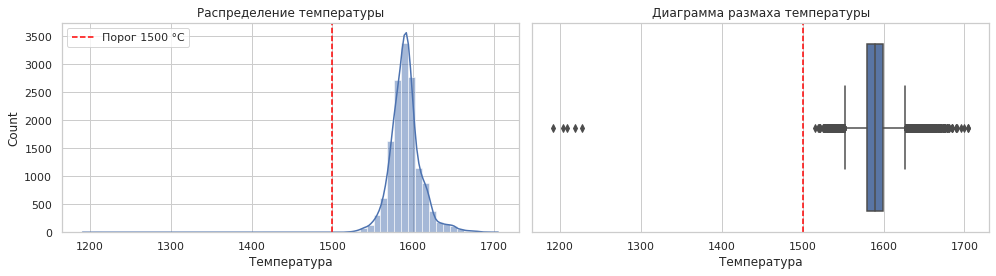

In [55]:
# Визуализация распределения температуры

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    data=temp,
    x='Температура',
    bins=60,
    kde=True,
    ax=axes[0]
)
axes[0].axvline(
    1500,
    color='red',
    linestyle='--',
    label='Порог 1500 °C'
)
axes[0].set_title('Распределение температуры')
axes[0].legend()

sns.boxplot(
    data=temp,
    x='Температура',
    ax=axes[1]
)
axes[1].axvline(
    1500,
    color='red',
    linestyle='--'
)
axes[1].set_title('Диаграмма размаха температуры')

plt.tight_layout()
plt.show()

In [56]:
# Определение положения каждого действительного замера внутри партии

valid_temp = (
    temp.dropna(subset=['Температура'])
    .sort_values(['key', 'Время замера'])
    .copy()
)

valid_temp['Номер_действительного_замера'] = (
    valid_temp.groupby('key').cumcount() + 1
)

valid_temp['Количество_действительных_замеров'] = (
    valid_temp.groupby('key')['Температура']
    .transform('size')
)

valid_temp['Положение_замера'] = np.select(
    [
        valid_temp['Количество_действительных_замеров'].eq(1),
        valid_temp['Номер_действительного_замера'].eq(1),
        valid_temp['Номер_действительного_замера'].eq(
            valid_temp['Количество_действительных_замеров']
        )
    ],
    [
        'единственный',
        'первый',
        'последний'
    ],
    default='промежуточный'
)

In [57]:
# Исследование аномальных температур ниже 1500 градусов

temperature_anomalies = valid_temp[
    valid_temp['Температура'] < 1500
].copy()

display(
    temperature_anomalies[
        [
            'key',
            'Время замера',
            'Температура',
            'Номер_действительного_замера',
            'Количество_действительных_замеров',
            'Положение_замера'
        ]
    ]
)

display(
    temperature_anomalies['Положение_замера']
    .value_counts()
    .to_frame('Количество аномалий')
)

print(
    'Количество партий с аномальной температурой:',
    temperature_anomalies['key'].nunique()
)

,key,Время замера,Температура,Номер_действительного_замера,Количество_действительных_замеров,Положение_замера
4883,867,2019-06-06 08:03:39,1191.000,1,8,первый
6784,1214,2019-06-18 08:01:03,1208.000,1,4,первый
9050,1619,2019-07-03 02:34:41,1218.000,1,3,первый
11495,2052,2019-07-25 08:49:15,1227.000,1,6,первый
14283,2561,2019-08-12 18:49:29,1204.000,1,1,единственный


,Количество аномалий
первый,4
единственный,1


Количество партий с аномальной температурой: 5


In [58]:
# Формирование списков партий, непригодных для моделирования

insufficient_temp_keys = set(
    valid_measurement_count[
        valid_measurement_count < 2
    ].index
)

anomalous_temp_keys = set(
    temperature_anomalies['key']
)

excluded_temp_keys = (
    insufficient_temp_keys |
    anomalous_temp_keys
)

temp_filter_summary = pd.Series({
    'Всего партий': temp['key'].nunique(),
    'Менее двух действительных замеров':
        len(insufficient_temp_keys),
    'Есть температура ниже 1500 °C':
        len(anomalous_temp_keys),
    'Одновременно обе причины':
        len(insufficient_temp_keys & anomalous_temp_keys),
    'Всего исключено уникальных партий':
        len(excluded_temp_keys),
    'Осталось пригодных партий':
        temp['key'].nunique() - len(excluded_temp_keys)
})

display(temp_filter_summary.to_frame('Количество партий'))

,Количество партий
Всего партий,3216
Менее двух действительных замеров,741
Есть температура ниже 1500 °C,5
Одновременно обе причины,1
Всего исключено уникальных партий,745
Осталось пригодных партий,2471


In [59]:
# Отбор действительных замеров пригодных партий

temp_valid_clean = (
    temp.dropna(subset=['Температура'])
    .loc[lambda df: ~df['key'].isin(excluded_temp_keys)]
    .sort_values(['key', 'Время замера'])
    .copy()
)

In [60]:
# Формирование начальной температуры и целевого признака

temp_prepared = (
    temp_valid_clean
    .groupby('key')
    .agg(
        Начальная_температура=(
            'Температура',
            'first'
        ),
        Конечная_температура=(
            'Температура',
            'last'
        )
    )
    .reset_index()
)

display(temp_prepared.head())

,key,Начальная_температура,Конечная_температура
0,1,1571.000,1613.000
1,2,1581.000,1602.000
2,3,1596.000,1599.000
3,4,1601.000,1625.000
4,5,1576.000,1602.000


In [61]:
# Проверка подготовленных температурных признаков

temp_prepared_overview = pd.Series({
    'Количество строк': len(temp_prepared),
    'Количество партий': temp_prepared['key'].nunique(),
    'Дубликаты ключей':
        temp_prepared['key'].duplicated().sum(),
    'Количество пропусков':
        temp_prepared.isna().sum().sum(),
    'Начальных температур ниже 1500 °C':
        temp_prepared['Начальная_температура'].lt(1500).sum(),
    'Конечных температур ниже 1500 °C':
        temp_prepared['Конечная_температура'].lt(1500).sum()
})

display(temp_prepared_overview.to_frame('Значение'))

,Значение
Количество строк,2471
Количество партий,2471
Дубликаты ключей,0
Количество пропусков,0
Начальных температур ниже 1500 °C,0
Конечных температур ниже 1500 °C,0


In [62]:
# Сравнение распределений начальной и конечной температуры

display(
    temp_prepared[
        [
            'Начальная_температура',
            'Конечная_температура'
        ]
    ]
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .T
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Начальная_температура,2471.000,1589.013,25.004,1519.000,1533.000,1550.000,1572.000,1588.000,1605.000,1633.000,1651.300,1679.000
Конечная_температура,2471.000,1595.340,16.035,1541.000,1570.000,1576.000,1587.000,1593.000,1599.000,1621.000,1661.300,1700.000


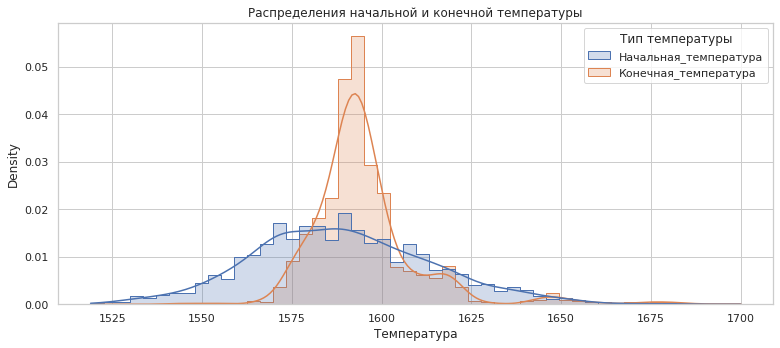

In [63]:
# Визуализация начальной и конечной температуры

temp_long = temp_prepared.melt(
    id_vars='key',
    value_vars=[
        'Начальная_температура',
        'Конечная_температура'
    ],
    var_name='Тип температуры',
    value_name='Температура'
)

plt.figure(figsize=(11, 5))

sns.histplot(
    data=temp_long,
    x='Температура',
    hue='Тип температуры',
    bins=50,
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Распределения начальной и конечной температуры')
plt.tight_layout()
plt.show()

In [64]:
# Исследовательский анализ изменения температуры

temperature_change = (
    temp_prepared['Конечная_температура'] -
    temp_prepared['Начальная_температура']
)

display(
    temperature_change
    .describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    .to_frame('Изменение температуры')
)

,Изменение температуры
count,2471.000
mean,6.327
std,23.056
min,-98.000
1%,-52.000
5%,-32.000
25%,-8.000
50%,7.000
75%,22.000
95%,43.000


#### Вывод по `data_temp`

Таблица содержала 18 092 наблюдения для 3216 партий. Полные дубликаты,
повторяющиеся комбинации номера партии и времени замера, а также пропуски
времени отсутствовали. В столбце температуры было обнаружено 3427 пропусков.

Для моделирования пригодны только партии, содержащие не менее двух
действительных измерений: первый замер используется как входной признак,
а последний — как целевой. У 741 партии присутствовал только один
действительный замер, поэтому такие партии были исключены.

Обнаружено пять температур ниже установленного заказчиком порога 1500 °C.
В четырёх случаях аномалия являлась первым замером, ещё в одном — единственным.
Все пять партий исключены полностью, поскольку удаление только аномальной
строки привело бы к использованию промежуточного измерения в качестве
начальной температуры.

После учёта пересечения причин исключено 745 уникальных партий. Итоговая
таблица содержит 2471 партию, начальную температуру и целевой признак —
конечную температуру. Промежуточные измерения, их количество и время
последнего замера в модель не передаются во избежание утечки целевого признака.

### Данные о проволочных материалах — `data_wire`

Таблица содержит объёмы девяти видов проволочных материалов, добавленных
в партии стали. Одной партии соответствует не более одной строки. Пропуск
означает, что материал соответствующего типа в партию не добавлялся.

In [65]:
# Создание рабочей копии и проверка структуры data_wire

wire = data_wire.copy()
wire_columns = wire.columns.drop('key')

wire_overview = pd.Series({
    'Количество строк': len(wire),
    'Количество партий': wire['key'].nunique(),
    'Дубликаты ключей': wire['key'].duplicated().sum(),
    'Полные дубликаты': wire.duplicated().sum(),
    'Количество пропусков':
        wire[wire_columns].isna().sum().sum()
})

display(wire_overview.to_frame('Значение'))

,Значение
Количество строк,3081
Количество партий,3081
Дубликаты ключей,0
Полные дубликаты,0
Количество пропусков,23385


In [66]:
# Анализ частоты использования проволочных материалов

wire_usage = pd.DataFrame({
    'Количество партий':
        wire[wire_columns].notna().sum(),

    'Доля партий, %':
        wire[wire_columns].notna().mean() * 100
}).sort_values(
    'Количество партий',
    ascending=False
)

display(wire_usage)

,Количество партий,"Доля партий, %"
Wire 1,3055,99.156
Wire 2,1079,35.021
Wire 6,73,2.369
Wire 3,63,2.045
Wire 9,29,0.941
Wire 8,19,0.617
Wire 4,14,0.454
Wire 7,11,0.357
Wire 5,1,0.032


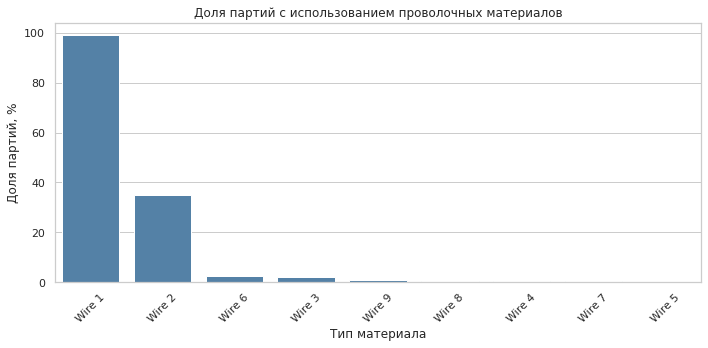

In [67]:
# Визуализация частоты использования проволочных материалов

plt.figure(figsize=(10, 5))

sns.barplot(
    data=wire_usage.reset_index(),
    x='index',
    y='Доля партий, %',
    color='steelblue'
)

plt.title('Доля партий с использованием проволочных материалов')
plt.xlabel('Тип материала')
plt.ylabel('Доля партий, %')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [68]:
# Проверка объёмов проволочных материалов на потенциальные аномалии

wire_quality = pd.DataFrame({
    'Непустых значений':
        wire[wire_columns].notna().sum(),

    'Нулевых значений':
        wire[wire_columns].eq(0).sum(),

    'Отрицательных значений':
        wire[wire_columns].lt(0).sum(),

    'Минимум':
        wire[wire_columns].min(),

    'Медиана':
        wire[wire_columns].median(),

    'Максимум':
        wire[wire_columns].max()
})

display(wire_quality)

,Непустых значений,Нулевых значений,Отрицательных значений,Минимум,Медиана,Максимум
Wire 1,3055,0,0,1.919,100.158,330.314
Wire 2,1079,0,0,0.030,40.143,282.780
Wire 3,63,0,0,0.144,235.195,385.009
Wire 4,14,0,0,24.149,45.234,113.231
Wire 5,1,0,0,15.132,15.132,15.132
Wire 6,73,0,0,0.034,42.076,180.455
Wire 7,11,0,0,0.234,9.017,32.848
Wire 8,19,0,0,45.077,46.280,102.762
Wire 9,29,0,0,4.623,30.066,90.054


In [69]:
# Проверка партий без проволочных материалов

wire_material_count = (
    wire[wire_columns].notna().sum(axis=1)
)

print(
    'Партий без проволочных материалов:',
    wire_material_count.eq(0).sum()
)

display(
    wire_material_count
    .describe()
    .to_frame('Количество типов материалов')
)

Партий без проволочных материалов: 0


,Количество типов материалов
count,3081.000
mean,1.410
std,0.578
min,1.000
25%,1.000
50%,1.000
75%,2.000
max,5.000


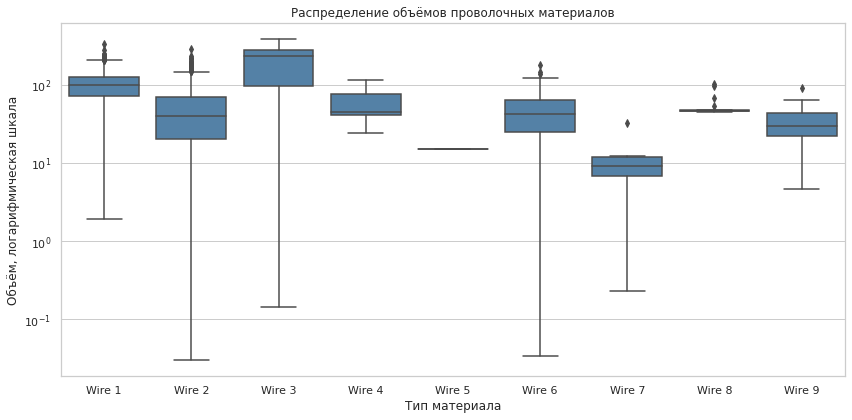

In [70]:
# Подготовка данных для визуализации объёмов проволочных материалов

wire_long = wire.melt(
    id_vars='key',
    value_vars=wire_columns,
    var_name='Материал',
    value_name='Объём'
).dropna()

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=wire_long,
    x='Материал',
    y='Объём',
    color='steelblue'
)

plt.yscale('log')
plt.title('Распределение объёмов проволочных материалов')
plt.xlabel('Тип материала')
plt.ylabel('Объём, логарифмическая шкала')
plt.tight_layout()
plt.show()

In [71]:
# Анализ верхних значений объёмов проволочных материалов

wire_quantiles = pd.DataFrame({
    'Количество наблюдений':
        wire[wire_columns].count(),

    'Медиана':
        wire[wire_columns].median(),

    '95%':
        wire[wire_columns].quantile(0.95),

    '99%':
        wire[wire_columns].quantile(0.99),

    'Максимум':
        wire[wire_columns].max()
})

display(wire_quantiles)

,Количество наблюдений,Медиана,95%,99%,Максимум
Wire 1,3055,100.158,171.544,209.267,330.314
Wire 2,1079,40.143,128.714,181.311,282.780
Wire 3,63,235.195,292.713,349.188,385.009
Wire 4,14,45.234,106.604,111.906,113.231
Wire 5,1,15.132,15.132,15.132,15.132
Wire 6,73,42.076,107.607,155.028,180.455
Wire 7,11,9.017,22.601,30.798,32.848
Wire 8,19,46.280,95.996,101.409,102.762
Wire 9,29,30.066,63.045,82.491,90.054


In [72]:
# Заполнение пропусков в объёмах проволочных материалов

wire[wire_columns] = (
    wire[wire_columns].fillna(0)
)

print(
    'Количество пропусков после заполнения:',
    wire[wire_columns].isna().sum().sum()
)

Количество пропусков после заполнения: 0


In [73]:
# Генерация признаков на основе проволочных материалов

wire['Общий_объём_проволочных'] = (
    wire[wire_columns].sum(axis=1)
)

wire['Количество_типов_проволочных'] = (
    wire[wire_columns].gt(0).sum(axis=1)
)

display(
    wire[
        [
            'Общий_объём_проволочных',
            'Количество_типов_проволочных'
        ]
    ].describe()
)

,Общий_объём_проволочных,Количество_типов_проволочных
count,3081.000,3081.000
mean,123.723,1.410
std,66.083,0.578
min,1.919,1.000
25%,86.112,1.000
50%,114.180,1.000
75%,150.181,2.000
max,663.852,5.000


In [74]:
# Формирование итоговой таблицы признаков проволочных материалов

wire_prepared = wire.copy()

wire_prepared_overview = pd.Series({
    'Количество строк': len(wire_prepared),
    'Количество партий':
        wire_prepared['key'].nunique(),
    'Дубликаты ключей':
        wire_prepared['key'].duplicated().sum(),
    'Количество пропусков':
        wire_prepared.isna().sum().sum()
})

display(wire_prepared_overview.to_frame('Значение'))

,Значение
Количество строк,3081
Количество партий,3081
Дубликаты ключей,0
Количество пропусков,0


#### Вывод по `data_wire`

Таблица содержит сведения о проволочных материалах для 3081 партии. Каждой
партии соответствует одна строка. Дубликаты ключей и полные дубликаты
отсутствуют.

В исходных данных было обнаружено 23 385 пропусков. Согласно условию задачи,
пропуск означает, что материал соответствующего типа в партию не добавлялся,
поэтому пропущенные значения были заменены нулями. После обработки пропуски
отсутствуют.

Отрицательных и исходных нулевых объёмов не обнаружено. В каждой представленной
партии использовался хотя бы один тип проволочного материала. Наиболее
распространён `Wire 1`: он использовался в 99,16% партий. `Wire 2` встречается
в 35,02% партий, остальные материалы применялись значительно реже. `Wire 5`
зафиксирован только в одной партии.

Однозначно ошибочных объёмов не обнаружено. Редкие и крайние значения
сохранены, поскольку допустимые технологические границы заказчиком не заданы.

Для каждой партии рассчитаны общий объём проволочных материалов и количество
использованных типов. В среднем использовалось 1,41 типа материала, медианное
значение равно одному. Средний общий объём составил 123,72.

Итоговая таблица содержит 3081 строку, уникальный ключ для каждой партии и не
содержит пропусков.

### Время подачи проволочных материалов — `data_wire_time`

Таблица содержит время подачи каждого типа проволочного материала. Одной
партии соответствует не более одной строки. Пропуск означает, что материал
соответствующего типа в партию не добавлялся.

In [75]:
# Создание рабочей копии и проверка структуры data_wire_time

wire_time = data_wire_time.copy()
wire_time_columns = wire_time.columns.drop('key')

wire_time_overview = pd.Series({
    'Количество строк': len(wire_time),
    'Количество партий': wire_time['key'].nunique(),
    'Дубликаты ключей': wire_time['key'].duplicated().sum(),
    'Полные дубликаты': wire_time.duplicated().sum(),
    'Количество пропусков': (
        wire_time[wire_time_columns].isna().sum().sum()
    )
})

display(wire_time_overview.to_frame('Значение'))

,Значение
Количество строк,3081
Количество партий,3081
Дубликаты ключей,0
Полные дубликаты,0
Количество пропусков,23385


In [76]:
# Определение общего временного диапазона подачи проволочных материалов

all_wire_times = (
    wire_time[wire_time_columns]
    .stack()
)

wire_time_range = pd.Series({
    'Самая ранняя подача': all_wire_times.min(),
    'Самая поздняя подача': all_wire_times.max(),
    'Количество временных отметок': len(all_wire_times)
})

display(wire_time_range.to_frame('Значение'))

,Значение
Самая ранняя подача,2019-05-03 11:06:19
Самая поздняя подача,2019-09-06 17:10:06
Количество временных отметок,4344


In [77]:
# Расчёт интервала между первой и последней подачей проволочных материалов

wire_time['Первая_подача_проволочных'] = (
    wire_time[wire_time_columns].min(axis=1)
)

wire_time['Последняя_подача_проволочных'] = (
    wire_time[wire_time_columns].max(axis=1)
)

wire_time['Интервал_подачи_проволочных_сек'] = (
    wire_time['Последняя_подача_проволочных'] -
    wire_time['Первая_подача_проволочных']
).dt.total_seconds()

display(
    wire_time['Интервал_подачи_проволочных_сек']
    .describe(
        percentiles=[
            0.01, 0.05, 0.25, 0.50,
            0.75, 0.95, 0.99
        ]
    )
    .to_frame()
)

,Интервал_подачи_проволочных_сек
count,3081.000
mean,214.519
std,396.132
min,0.000
1%,0.000
5%,0.000
25%,0.000
50%,0.000
75%,401.000
95%,802.000


In [78]:
# Проверка интервалов подачи проволочных материалов

wire_time_quality = pd.Series({
    'Отрицательных интервалов':
        wire_time['Интервал_подачи_проволочных_сек'].lt(0).sum(),

    'Нулевых интервалов':
        wire_time['Интервал_подачи_проволочных_сек'].eq(0).sum(),

    'Интервалов больше одного часа':
        wire_time['Интервал_подачи_проволочных_сек'].gt(3600).sum(),

    'Интервалов больше суток':
        wire_time['Интервал_подачи_проволочных_сек'].gt(86400).sum(),

    'Пропущенных рассчитанных интервалов':
        wire_time['Интервал_подачи_проволочных_сек'].isna().sum()
})

display(wire_time_quality.to_frame('Количество партий'))

,Количество партий
Отрицательных интервалов,0
Нулевых интервалов,1951
Интервалов больше одного часа,3
Интервалов больше суток,0
Пропущенных рассчитанных интервалов,0


In [79]:
# Просмотр партий с наиболее длительной подачей проволочных материалов

display(
    wire_time[
        [
            'key',
            'Первая_подача_проволочных',
            'Последняя_подача_проволочных',
            'Интервал_подачи_проволочных_сек'
        ]
    ]
    .nlargest(
        10,
        'Интервал_подачи_проволочных_сек'
    )
)

,key,Первая_подача_проволочных,Последняя_подача_проволочных,Интервал_подачи_проволочных_сек
2012,2110,2019-07-27 19:11:22,2019-07-27 20:50:19,5937.000
2010,2108,2019-07-27 13:43:32,2019-07-27 15:15:04,5492.000
2439,2566,2019-08-13 02:52:06,2019-08-13 04:15:39,5013.000
2440,2567,2019-08-13 06:10:36,2019-08-13 07:10:14,3578.000
97,113,2019-05-07 14:46:05,2019-05-07 15:44:02,3477.000
2009,2107,2019-07-27 07:56:34,2019-07-27 08:54:09,3455.000
98,114,2019-05-07 16:16:34,2019-05-07 17:12:49,3375.000
2008,2106,2019-07-27 05:49:05,2019-07-27 06:35:10,2765.000
928,988,2019-06-10 15:07:04,2019-06-10 15:53:05,2761.000
1867,1958,2019-07-21 10:04:47,2019-07-21 10:47:15,2548.000


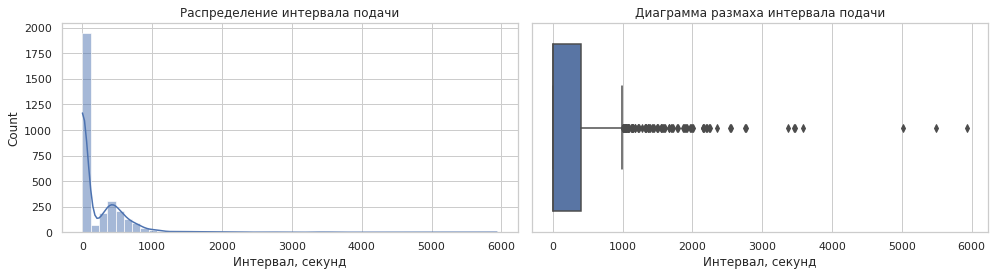

In [80]:
# Визуализация интервала подачи проволочных материалов

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    data=wire_time,
    x='Интервал_подачи_проволочных_сек',
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Распределение интервала подачи')
axes[0].set_xlabel('Интервал, секунд')

sns.boxplot(
    data=wire_time,
    x='Интервал_подачи_проволочных_сек',
    ax=axes[1]
)
axes[1].set_title('Диаграмма размаха интервала подачи')
axes[1].set_xlabel('Интервал, секунд')

plt.tight_layout()
plt.show()

In [81]:
# Формирование итоговой таблицы временных признаков проволочных материалов

wire_time_prepared = wire_time[
    [
        'key',
        'Интервал_подачи_проволочных_сек'
    ]
].copy()

wire_time_prepared_overview = pd.Series({
    'Количество строк': len(wire_time_prepared),
    'Количество партий':
        wire_time_prepared['key'].nunique(),
    'Дубликаты ключей':
        wire_time_prepared['key'].duplicated().sum(),
    'Количество пропусков':
        wire_time_prepared.isna().sum().sum()
})

display(wire_time_prepared_overview.to_frame('Значение'))

,Значение
Количество строк,3081
Количество партий,3081
Дубликаты ключей,0
Количество пропусков,0


#### Вывод по `data_wire_time`

Таблица содержит время подачи проволочных материалов для 3081 партии.
Дубликаты ключей и полные дубликаты отсутствуют. Пропуски соответствуют
материалам, которые не добавлялись в партию, поэтому их заполнение не
требуется.

Временные отметки находятся в диапазоне с 3 мая по 6 сентября 2019 года.
Отрицательных интервалов, пропущенных рассчитанных интервалов и интервалов
продолжительностью более суток не обнаружено.

В 1951 партии интервал равен нулю, поскольку в большинстве таких партий
использовался только один тип проволочного материала. Только в трёх партиях
интервал между первой и последней подачей превышал один час. Максимальное
значение составило 5937 секунд — около 1 часа 39 минут.

С учётом предупреждения заказчика об асинхронности временных показаний
продолжительные интервалы не признаны ошибочными и сохранены. Абсолютные даты
не используются как признаки. Для дальнейшего анализа сохранён относительный
интервал между первой и последней подачей проволочных материалов.

## Объединение подготовленных таблиц

Основой итогового набора данных является таблица `temp_prepared`, поскольку
она определяет список пригодных партий, начальную температуру и целевой
признак. Перед объединением необходимо проверить наличие этих партий в
остальных источниках.

In [82]:
# Проверка покрытия пригодных партий в подготовленных таблицах

base_keys = set(temp_prepared['key'])

prepared_tables = {
    'arc': arc_aggregated,
    'gas': gas_prepared,
    'bulk': bulk_prepared,
    'bulk_time': bulk_time_prepared,
    'wire': wire_prepared,
    'wire_time': wire_time_prepared
}

coverage_summary = []

for table_name, df in prepared_tables.items():
    table_keys = set(df['key'])

    coverage_summary.append({
        'Таблица': table_name,
        'Всего ключей в таблице': len(table_keys),
        'Совпадает с temp_prepared':
            len(base_keys & table_keys),
        'Отсутствует для temp_prepared':
            len(base_keys - table_keys),
        'Нет в temp_prepared':
            len(table_keys - base_keys)
    })

coverage_summary = pd.DataFrame(coverage_summary)

display(coverage_summary)

,Таблица,Всего ключей в таблице,Совпадает с temp_prepared,Отсутствует для temp_prepared,Нет в temp_prepared
0,arc,3213,2470,1,743
1,gas,3239,2469,2,770
2,bulk,3129,2403,68,726
3,bulk_time,3129,2403,68,726
4,wire,3081,2368,103,713
5,wire_time,3081,2368,103,713


In [83]:
# Формирование карты наличия данных по каждой пригодной партии

key_coverage = pd.DataFrame({
    'key': sorted(base_keys)
})

for table_name, df in prepared_tables.items():
    key_coverage[table_name] = (
        key_coverage['key'].isin(df['key'])
    )

display(key_coverage.head())
display(key_coverage.drop(columns='key').sum().to_frame('Есть данные'))

,key,arc,gas,bulk,bulk_time,wire,wire_time
0,1,True,True,True,True,True,True
1,2,True,True,True,True,True,True
2,3,True,True,True,True,True,True
3,4,True,True,True,True,True,True
4,5,True,True,True,True,True,True


,Есть данные
arc,2470
gas,2469
bulk,2403
bulk_time,2403
wire,2368
wire_time,2368


In [84]:
# Определение партий без обязательных технологических данных

temp_keys = set(temp_prepared['key'])
arc_keys = set(arc_aggregated['key'])
gas_keys = set(gas_prepared['key'])

missing_arc_keys = temp_keys - arc_keys
missing_gas_keys = temp_keys - gas_keys
missing_mandatory_keys = (
    missing_arc_keys |
    missing_gas_keys
)

mandatory_key_summary = pd.Series({
    'Нет данных о нагреве': len(missing_arc_keys),
    'Нет данных о газе': len(missing_gas_keys),
    'Нет одновременно нагрева и газа':
        len(missing_arc_keys & missing_gas_keys),
    'Всего исключаемых уникальных партий':
        len(missing_mandatory_keys),
    'Останется партий':
        len(temp_keys - missing_mandatory_keys)
})

display(mandatory_key_summary.to_frame('Количество'))

print('Ключи без нагрева:', sorted(missing_arc_keys))
print('Ключи без газа:', sorted(missing_gas_keys))

,Количество
Нет данных о нагреве,1
Нет данных о газе,2
Нет одновременно нагрева и газа,0
Всего исключаемых уникальных партий,3
Останется партий,2468


Ключи без нагрева: [2116]
Ключи без газа: [193, 259]


In [85]:
# Объединение температуры с обязательными данными о нагреве и газе

final_data = (
    temp_prepared
    .merge(
        arc_aggregated,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        gas_prepared,
        on='key',
        how='inner',
        validate='one_to_one'
    )
)

print(
    'Количество партий после обязательных объединений:',
    len(final_data)
)

Количество партий после обязательных объединений: 2468


In [86]:
# Объединение подготовленных таблиц по общим партиям

final_data = (
    temp_prepared
    .merge(
        arc_aggregated,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        gas_prepared,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        bulk_prepared,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        bulk_time_prepared,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        wire_prepared,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        wire_time_prepared,
        on='key',
        how='inner',
        validate='one_to_one'
    )
    .sort_values('key')
    .reset_index(drop=True)
)

print(
    'Количество партий после объединения всех таблиц:',
    len(final_data)
)

Количество партий после объединения всех таблиц: 2324


In [87]:
# Формирование списка необязательных материальных признаков

bulk_feature_columns = (
    bulk_prepared.columns.drop('key').tolist()
)

wire_feature_columns = (
    wire_prepared.columns.drop('key').tolist()
)

time_feature_columns = [
    'Интервал_подачи_сыпучих_сек',
    'Интервал_подачи_проволочных_сек'
]

optional_feature_columns = (
    bulk_feature_columns +
    wire_feature_columns +
    time_feature_columns
)

In [88]:
# Проверка объединённой таблицы после заполнения пропусков

final_data_overview = pd.Series({
    'Количество строк': len(final_data),
    'Количество столбцов': final_data.shape[1],
    'Количество партий': final_data['key'].nunique(),
    'Дубликаты ключей':
        final_data['key'].duplicated().sum(),
    'Количество пропусков':
        final_data.isna().sum().sum(),
    'Количество бесконечных значений': (
        np.isinf(
            final_data.select_dtypes(include='number')
        ).sum().sum()
    )
})

display(final_data_overview.to_frame('Значение'))

,Значение
Количество строк,2324
Количество столбцов,46
Количество партий,2324
Дубликаты ключей,0
Количество пропусков,0
Количество бесконечных значений,0


###  Вывод по объединению данных

Основой объединённой таблицы стали 2471 партия с корректными начальной и конечной температурами. Для построения модели отбирались только партии, по которым присутствует информация обо всех рассматриваемых этапах технологического процесса:

- нагреве электродами;
- продувке сплава газом;
- подаче сыпучих материалов и времени их подачи;
- подаче проволочных материалов и времени их подачи.

Все подготовленные таблицы были объединены по столбцу `key` с помощью внутреннего объединения. Поэтому партии, отсутствующие хотя бы в одной из таблиц, были исключены как наблюдения с неполной информацией о производственном процессе.

В результате объединения осталось 2324 партии. Таким образом, относительно подготовленной таблицы температур было исключено 147 уникальных партий, для которых отсутствовали данные хотя бы об одном из рассматриваемых технологических этапов.

Пропуски в отдельных столбцах с объёмами сыпучих и проволочных материалов были обработаны до объединения: они означают, что соответствующий тип материала в партию не добавлялся, и поэтому были заменены нулями. При этом отсутствие всей партии в одной из таблиц не интерпретировалось как отсутствие операции и не заменялось нулевыми значениями.

Итоговая таблица содержит 2324 строки, каждой партии соответствует одна строка. Дубликаты ключей, пропуски и бесконечные значения отсутствуют. Столбец `Конечная_температура` является целевым признаком, а `key` используется только как идентификатор партии и не будет передаваться модели.

## Контроль и исследовательский анализ объединённых данных

In [89]:
# Определение идентификатора, целевого и входных признаков

identifier_column = 'key'
target_column = 'Конечная_температура'

feature_columns = [
    column
    for column in final_data.columns
    if column not in [
        identifier_column,
        target_column
    ]
]

print('Количество входных признаков:', len(feature_columns))
print('Целевой признак:', target_column)
print('Идентификатор:', identifier_column)

Количество входных признаков: 44
Целевой признак: Конечная_температура
Идентификатор: key


In [90]:
# Расчёт описательной статистики объединённых данных

final_statistics = (
    final_data[
        feature_columns + [target_column]
    ]
    .describe(
        percentiles=[
            0.01, 0.05, 0.25, 0.50,
            0.75, 0.95, 0.99
        ]
    )
    .T
)

display(final_statistics)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Начальная_температура,2324.000,1587.369,23.628,1519.000,1533.000,1550.000,1571.000,1587.000,1603.000,1628.000,1644.770,1660.000
Количество_нагревов,2324.000,4.697,1.606,1.000,1.000,2.000,4.000,5.000,6.000,7.000,9.000,16.000
Общая_длительность_нагрева,2324.000,808.197,340.814,57.000,173.000,318.000,581.000,778.000,993.000,1383.700,1834.770,4189.000
Средняя_длительность_нагрева,2324.000,172.118,43.740,57.000,82.345,107.515,141.000,169.500,198.750,249.592,294.827,378.000
Максимальная_длительность_нагрева,2324.000,289.764,107.180,57.000,119.230,143.000,212.000,277.000,339.000,492.850,617.540,907.000
Средняя_активная_мощность,2324.000,0.664,0.128,0.268,0.403,0.471,0.576,0.656,0.742,0.896,0.994,1.244
Средняя_реактивная_мощность,2324.000,0.489,0.098,0.196,0.291,0.339,0.420,0.485,0.547,0.661,0.749,0.961
Средняя_полная_мощность,2324.000,0.826,0.160,0.332,0.498,0.581,0.714,0.818,0.921,1.115,1.234,1.572
Среднее_соотношение_мощностей,2324.000,1.372,0.066,1.100,1.216,1.259,1.329,1.372,1.415,1.479,1.524,1.663
Средний_коэффициент_мощности,2324.000,0.805,0.014,0.740,0.770,0.781,0.797,0.806,0.815,0.828,0.835,0.857


In [91]:
# Анализ уникальности и доли нулевых значений признаков

feature_profile = pd.DataFrame({
    'Уникальных значений':
        final_data[feature_columns].nunique(),

    'Нулевых значений':
        final_data[feature_columns].eq(0).sum(),

    'Доля нулей, %':
        final_data[feature_columns].eq(0).mean() * 100,

    'Стандартное отклонение':
        final_data[feature_columns].std()
}).sort_values(
    'Доля нулей, %',
    ascending=False
)

display(feature_profile)

,Уникальных значений,Нулевых значений,"Доля нулей, %",Стандартное отклонение
Wire 5,1,2324,100.000,0.000
Bulk 8,2,2323,99.957,1.016
Wire 7,5,2320,99.828,0.206
Wire 4,13,2312,99.484,4.763
Bulk 9,10,2311,99.441,6.227
Wire 8,10,2311,99.441,4.407
Bulk 7,14,2311,99.441,30.709
Bulk 2,13,2311,99.441,19.103
Bulk 13,11,2310,99.398,14.250
Wire 9,22,2300,98.967,3.460


In [92]:
# Расчёт корреляций признаков с конечной температурой

correlation_data = final_data[
    feature_columns + [target_column]
]

pearson_target = (
    correlation_data
    .corr(method='pearson')[target_column]
    .drop(target_column)
)

spearman_target = (
    correlation_data
    .corr(method='spearman')[target_column]
    .drop(target_column)
)

target_correlations = pd.DataFrame({
    'Корреляция Пирсона': pearson_target,
    'Корреляция Спирмена': spearman_target
})

target_correlations['Максимальная абсолютная корреляция'] = (
    target_correlations.abs().max(axis=1)
)

target_correlations = target_correlations.sort_values(
    'Максимальная абсолютная корреляция',
    ascending=False
)

display(target_correlations)

,Корреляция Пирсона,Корреляция Спирмена,Максимальная абсолютная корреляция
Wire 1,0.317,0.298,0.317
Начальная_температура,0.302,0.309,0.309
Общая_длительность_нагрева,0.278,0.236,0.278
Bulk 12,0.267,0.240,0.267
Bulk 15,0.266,0.226,0.266
Bulk 6,-0.181,-0.263,0.263
Общая_активная_энергия,0.258,0.221,0.258
Общая_полная_энергия,0.256,0.219,0.256
Общая_реактивная_энергия,0.251,0.214,0.251
Wire 2,-0.207,-0.236,0.236


**Выбор метода корреляции.** Большинство входных признаков имеет распределение, отличное от нормального: признаки объёмов материалов содержат большое количество нулей, а продолжительность нагрева, энергия, объём газа и интервалы подачи имеют выраженную асимметрию и редкие большие значения. Поэтому основным методом оценки связи выбран коэффициент корреляции Спирмена: он рассчитывается по рангам, устойчивее к выбросам и позволяет оценивать монотонные, но не обязательно линейные зависимости. Коэффициент Пирсона приведён дополнительно для сравнения и оценки линейной связи между признаками.

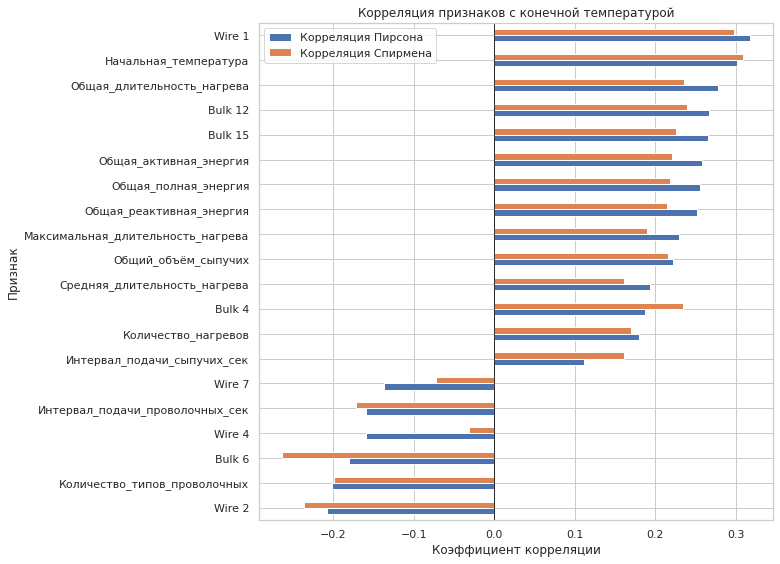

In [93]:
# Визуализация корреляций признаков с целевым признаком

top_correlation_features = (
    target_correlations
    .head(20)
    .drop(columns='Максимальная абсолютная корреляция')
    .sort_values('Корреляция Пирсона')
)

top_correlation_features.plot(
    kind='barh',
    figsize=(11, 8)
)

plt.title('Корреляция признаков с конечной температурой')
plt.xlabel('Коэффициент корреляции')
plt.ylabel('Признак')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [94]:
# Поиск сильно коррелирующих пар входных признаков

feature_correlation = (
    final_data[feature_columns]
    .corr(method='pearson')
)

upper_triangle = feature_correlation.where(
    np.triu(
        np.ones(feature_correlation.shape),
        k=1
    ).astype(bool)
)

strong_feature_correlations = (
    upper_triangle
    .stack()
    .rename('Корреляция')
    .reset_index()
    .rename(
        columns={
            'level_0': 'Признак 1',
            'level_1': 'Признак 2'
        }
    )
)

strong_feature_correlations = (
    strong_feature_correlations[
        strong_feature_correlations['Корреляция'].abs() >= 0.90
    ]
    .assign(
        Абсолютная_корреляция=lambda df:
            df['Корреляция'].abs()
    )
    .sort_values(
        'Абсолютная_корреляция',
        ascending=False
    )
)

display(strong_feature_correlations)

,Признак 1,Признак 2,Корреляция,Абсолютная_корреляция
376,Общая_активная_энергия,Общая_полная_энергия,0.999,0.999
407,Общая_реактивная_энергия,Общая_полная_энергия,0.997,0.997
201,Средняя_активная_мощность,Средняя_полная_мощность,0.995,0.995
308,Среднее_соотношение_мощностей,Средний_коэффициент_мощности,0.994,0.994
375,Общая_активная_энергия,Общая_реактивная_энергия,0.994,0.994
237,Средняя_реактивная_мощность,Средняя_полная_мощность,0.986,0.986
708,Bulk 9,Wire 8,0.975,0.975
200,Средняя_активная_мощность,Средняя_реактивная_мощность,0.965,0.965
90,Общая_длительность_нагрева,Общая_активная_энергия,0.902,0.902
92,Общая_длительность_нагрева,Общая_полная_энергия,0.900,0.900


In [95]:
# Определение постоянных и крайне разреженных признаков

minimum_nonzero_share = 0.01

minimum_nonzero_count = int(
    np.ceil(
        len(final_data) *
        minimum_nonzero_share
    )
)

nonzero_count = (
    final_data[feature_columns].ne(0).sum()
)

constant_columns = [
    column
    for column in feature_columns
    if final_data[column].nunique() <= 1
]

rare_columns = [
    column
    for column in feature_columns
    if (
        0 < nonzero_count[column] <
        minimum_nonzero_count
    )
]

print(
    'Минимальное количество ненулевых наблюдений:',
    minimum_nonzero_count
)
print('Постоянные признаки:', constant_columns)
print('Крайне редкие признаки:', rare_columns)

Минимальное количество ненулевых наблюдений: 24
Постоянные признаки: ['Wire 5']
Крайне редкие признаки: ['Bulk 2', 'Bulk 7', 'Bulk 8', 'Bulk 9', 'Bulk 13', 'Wire 4', 'Wire 7', 'Wire 8']


In [96]:
# Определение математически дублирующих признаков

redundant_columns = [
    'Средняя_полная_мощность',
    'Среднее_соотношение_мощностей',
    'Общая_реактивная_энергия',
    'Общая_полная_энергия'
]

columns_to_drop = sorted(
    set(
        constant_columns +
        rare_columns +
        redundant_columns
    )
)

display(
    pd.Series(
        columns_to_drop,
        name='Исключаемый признак'
    ).to_frame()
)

,Исключаемый признак
0,Bulk 13
1,Bulk 2
2,Bulk 7
3,Bulk 8
4,Bulk 9
5,Wire 4
6,Wire 5
7,Wire 7
8,Wire 8
9,Общая_полная_энергия


In [97]:
# Формирование набора данных для моделирования

model_data = (
    final_data
    .drop(columns=columns_to_drop)
    .copy()
)

model_feature_columns = [
    column
    for column in model_data.columns
    if column not in [
        identifier_column,
        target_column
    ]
]

model_data_overview = pd.Series({
    'Количество строк': len(model_data),
    'Количество столбцов': model_data.shape[1],
    'Количество входных признаков':
        len(model_feature_columns),
    'Количество пропусков':
        model_data.isna().sum().sum(),
    'Дубликаты ключей':
        model_data['key'].duplicated().sum()
})

display(model_data_overview.to_frame('Значение'))

,Значение
Количество строк,2324
Количество столбцов,33
Количество входных признаков,31
Количество пропусков,0
Дубликаты ключей,0


### Вывод по исследованию объединённых данных

Итоговая таблица содержит 2468 партий и 44 входных признака. Пропуски,
бесконечные значения и дубликаты ключей отсутствуют.

Наиболее сильная линейная связь с конечной температурой обнаружена у начальной
температуры. Умеренные связи также наблюдаются у количества типов проволочных
материалов, длительности нагрева, энергии и некоторых видов добавок.
Подозрительно высокой корреляции с целевым признаком не обнаружено, что
свидетельствует об отсутствии очевидной утечки.

Признак `Wire 5` оказался постоянным, поскольку единственная партия с этим
материалом не вошла в итоговую выборку. Несколько материалов встречаются менее
чем в 1% партий; такие признаки не позволяют надёжно оценить влияние материала
и создают риск переобучения.

Также обнаружены сильные ожидаемые корреляции между математически связанными
признаками мощности и энергии. Для уменьшения избыточности исключены постоянные,
крайне редкие и часть дублирующих производных признаков. Исходная объединённая
таблица сохранена для возможного сравнения полного и сокращённого наборов на
кросс-валидации.

## Подготовка данных для моделирования

Из объединённой таблицы были исключены постоянные, крайне редкие и
математически избыточные признаки. После отбора осталось 31 входной признак.
Идентификатор партии `key` не используется при обучении. Целевым признаком
является конечная температура.

In [98]:
# Разделение данных на входные и целевой признаки

X = model_data.drop(
    columns=[
        identifier_column,
        target_column
    ]
)

y = model_data[target_column]

print('Размер матрицы признаков:', X.shape)
print('Размер целевого признака:', y.shape)

Размер матрицы признаков: (2324, 31)
Размер целевого признака: (2324,)


In [99]:
# Разделение данных на тренировочную и тестовую выборки

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

split_overview = pd.Series({
    'Объектов в тренировочной выборке':
        len(X_train),
    'Объектов в тестовой выборке':
        len(X_test),
    'Признаков':
        X_train.shape[1],
    'Доля тестовой выборки':
        len(X_test) / len(X)
})

display(split_overview.to_frame('Значение'))

,Значение
Объектов в тренировочной выборке,1743.000
Объектов в тестовой выборке,581.000
Признаков,31.000
Доля тестовой выборки,0.250


In [100]:
# Настройка кросс-валидации для сравнения моделей

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [101]:
# Оценка константной модели на кросс-валидации

dummy_model = DummyRegressor(
    strategy='median'
)

dummy_cv_scores = -cross_val_score(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

dummy_result = pd.Series({
    'Среднее MAE':
        dummy_cv_scores.mean(),
    'Стандартное отклонение MAE':
        dummy_cv_scores.std(),
    'Минимальное MAE':
        dummy_cv_scores.min(),
    'Максимальное MAE':
        dummy_cv_scores.max()
})

display(dummy_result.to_frame('DummyRegressor'))

,DummyRegressor
Среднее MAE,8.048
Стандартное отклонение MAE,0.450
Минимальное MAE,7.598
Максимальное MAE,8.616


## Обучение и сравнение моделей

На тренировочной выборке будут сравнены линейная модель, случайный лес,
градиентный бустинг и нейронная сеть. Качество оценивается метрикой MAE
на пяти блоках кросс-валидации. Для моделей, чувствительных к масштабу,
стандартизация выполняется внутри пайплайна.

In [102]:
# Создание линейной модели со стандартизацией

ridge_model = Pipeline([
    (
        'scaler',
        StandardScaler()
    ),
    (
        'model',
        Ridge(
            alpha=1.0
        )
    )
])

In [103]:
# Создание модели случайного леса

random_forest_model = RandomForestRegressor(
    n_estimators=400,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=RANDOM_STATE,
    n_jobs=1
)

In [104]:
# Создание модели градиентного бустинга

boosting_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=400,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=RANDOM_STATE
)

In [105]:
# Создание нейронной сети с масштабированием признаков и цели

mlp_pipeline = Pipeline([
    (
        'scaler',
        StandardScaler()
    ),
    (
        'model',
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            alpha=0.001,
            learning_rate_init=0.001,
            early_stopping=True,
            validation_fraction=0.15,
            max_iter=1500,
            random_state=RANDOM_STATE
        )
    )
])

mlp_model = TransformedTargetRegressor(
    regressor=mlp_pipeline,
    transformer=StandardScaler()
)

In [106]:
# Формирование набора моделей для сравнения

models = {
    'DummyRegressor': dummy_model,
    'Ridge': ridge_model,
    'RandomForest': random_forest_model,
    'HistGradientBoosting': boosting_model,
    'MLPRegressor': mlp_model
}

In [107]:
# Оценка моделей на кросс-валидации

model_results = []

for model_name, model in models.items():
    cv_result = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        return_train_score=False
    )

    mae_scores = -cv_result['test_score']

    model_results.append({
        'Модель': model_name,
        'Среднее MAE': mae_scores.mean(),
        'Стандартное отклонение MAE':
            mae_scores.std(),
        'Минимальное MAE':
            mae_scores.min(),
        'Максимальное MAE':
            mae_scores.max(),
        'Среднее время обучения, сек':
            cv_result['fit_time'].mean()
    })

model_results = (
    pd.DataFrame(model_results)
    .sort_values('Среднее MAE')
    .reset_index(drop=True)
)

display(model_results)

,Модель,Среднее MAE,Стандартное отклонение MAE,Минимальное MAE,Максимальное MAE,"Среднее время обучения, сек"
0,Ridge,6.264,0.324,5.917,6.791,0.080
1,RandomForest,6.285,0.306,5.802,6.667,4.144
2,HistGradientBoosting,6.381,0.235,5.994,6.631,14.106
3,MLPRegressor,6.453,0.253,6.183,6.837,4.598
4,DummyRegressor,8.048,0.450,7.598,8.616,0.001


### Подбор гиперпараметров случайного леса

Случайный лес показал лучшее среднее значение MAE среди рассмотренных моделей.
Для улучшения качества выполняется автоматизированный подбор числа деревьев,
максимальной глубины, минимального количества объектов в листе и узле,
а также доли признаков, рассматриваемых при каждом разбиении.

In [108]:
# Настройка пространства гиперпараметров случайного леса

rf_parameter_distributions = {
    'n_estimators': [
        300, 500, 700
    ],
    'max_depth': [
        None, 8, 12, 16, 20
    ],
    'min_samples_split': [
        2, 4, 6, 10
    ],
    'min_samples_leaf': [
        1, 2, 3, 4
    ],
    'max_features': [
        0.5, 0.7, 0.9, 1.0
    ]
}

In [109]:
# Создание автоматизированного поиска параметров

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    param_distributions=rf_parameter_distributions,
    n_iter=20,
    scoring='neg_mean_absolute_error',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [110]:
# Подбор гиперпараметров на тренировочной выборке

rf_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=200726, shuffle=True),
                   estimator=RandomForestRegressor(n_jobs=1,
                                                   random_state=200726),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'max_depth': [None, 8, 12, 16, 20],
                                        'max_features': [0.5, 0.7, 0.9, 1.0],
                                        'min_samples_leaf': [1, 2, 3, 4],
                                        'min_samples_split': [2, 4, 6, 10],
                                        'n_estimators': [300, 500, 700]},
                   random_state=200726, return_train_score=True,
                   scoring='neg_mean_absolute_error', verbose=1)

In [111]:
# Вывод лучших параметров и качества случайного леса

best_rf_model = rf_search.best_estimator_
best_rf_cv_mae = -rf_search.best_score_

print('Лучшие параметры:')
display(rf_search.best_params_)

print(
    f'Лучшее среднее MAE на кросс-валидации: '
    f'{best_rf_cv_mae:.3f}'
)

Лучшие параметры:


{'n_estimators': 700,
 'min_samples_split': 4,
 'min_samples_leaf': 4,
 'max_features': 1.0,
 'max_depth': 20}

Лучшее среднее MAE на кросс-валидации: 6.267


In [112]:
# Формирование таблицы результатов подбора гиперпараметров

rf_search_results = pd.DataFrame(
    rf_search.cv_results_
)

rf_search_results['Среднее MAE validation'] = (
    -rf_search_results['mean_test_score']
)

rf_search_results['Стандартное отклонение MAE'] = (
    rf_search_results['std_test_score']
)

rf_search_results['Среднее MAE train'] = (
    -rf_search_results['mean_train_score']
)

rf_top_results = (
    rf_search_results[
        [
            'params',
            'Среднее MAE validation',
            'Стандартное отклонение MAE',
            'Среднее MAE train',
            'mean_fit_time'
        ]
    ]
    .sort_values('Среднее MAE validation')
    .head(10)
)

display(rf_top_results)

,params,Среднее MAE validation,Стандартное отклонение MAE,Среднее MAE train,mean_fit_time
9,"{'n_estimators': 700, 'min_samples_split': 4, ...",6.267,0.300,3.372,7.762
4,"{'n_estimators': 500, 'min_samples_split': 6, ...",6.268,0.310,2.972,5.905
18,"{'n_estimators': 500, 'min_samples_split': 2, ...",6.269,0.295,3.391,4.730
0,"{'n_estimators': 500, 'min_samples_split': 10,...",6.271,0.316,3.311,5.757
19,"{'n_estimators': 300, 'min_samples_split': 6, ...",6.274,0.307,2.915,3.180
12,"{'n_estimators': 500, 'min_samples_split': 2, ...",6.275,0.311,3.174,5.001
8,"{'n_estimators': 300, 'min_samples_split': 2, ...",6.282,0.299,2.976,3.581
13,"{'n_estimators': 300, 'min_samples_split': 2, ...",6.282,0.301,2.723,3.285
6,"{'n_estimators': 700, 'min_samples_split': 10,...",6.284,0.297,3.513,5.562
15,"{'n_estimators': 300, 'min_samples_split': 6, ...",6.286,0.294,3.664,2.722


### Подбор гиперпараметров градиентного бустинга

Градиентный бустинг показал качество, близкое к случайному лесу, и более низкий
разброс MAE между блоками кросс-валидации. Для модели подбираются скорость
обучения, количество итераций, сложность деревьев, минимальное количество
объектов в листе и коэффициент регуляризации.

In [113]:
# Настройка пространства гиперпараметров градиентного бустинга

boosting_parameter_distributions = {
    'learning_rate': [
        0.02, 0.03, 0.05, 0.08, 0.1
    ],
    'max_iter': [
        200, 400, 600, 800
    ],
    'max_leaf_nodes': [
        7, 15, 31, 63
    ],
    'max_depth': [
        None, 4, 6, 8
    ],
    'min_samples_leaf': [
        10, 20, 30, 40
    ],
    'l2_regularization': [
        0.0, 0.1, 1.0, 5.0, 10.0
    ]
}

In [114]:
# Создание автоматизированного поиска параметров бустинга

boosting_search = RandomizedSearchCV(
    estimator=HistGradientBoostingRegressor(
        loss='least_absolute_deviation',
        random_state=RANDOM_STATE
    ),
    param_distributions=boosting_parameter_distributions,
    n_iter=20,
    scoring='neg_mean_absolute_error',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [115]:
# Подбор гиперпараметров градиентного бустинга

boosting_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=200726, shuffle=True),
                   estimator=HistGradientBoostingRegressor(loss='least_absolute_deviation',
                                                           random_state=200726),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'l2_regularization': [0.0, 0.1, 1.0,
                                                              5.0, 10.0],
                                        'learning_rate': [0.02, 0.03, 0.05,
                                                          0.08, 0.1],
                                        'max_depth': [None, 4, 6, 8],
                                        'max_iter': [200, 400, 600, 800],
                                        'max_leaf_nodes': [7, 15, 31, 63],
                                        'min_samples_leaf': [10, 20, 30, 40]},
                   random_state=200726, return_train_score=True,
                   scoring='neg_mean_absolute_erro

In [116]:
# Вывод лучших параметров градиентного бустинга

best_boosting_model = (
    boosting_search.best_estimator_
)

best_boosting_cv_mae = (
    -boosting_search.best_score_
)

print('Лучшие параметры:')
display(boosting_search.best_params_)

print(
    f'Лучшее среднее MAE на кросс-валидации: '
    f'{best_boosting_cv_mae:.3f}'
)

Лучшие параметры:


{'min_samples_leaf': 20,
 'max_leaf_nodes': 31,
 'max_iter': 600,
 'max_depth': 4,
 'learning_rate': 0.05,
 'l2_regularization': 5.0}

Лучшее среднее MAE на кросс-валидации: 6.061


In [117]:
# Сравнение настроенного леса и градиентного бустинга

tuned_model_comparison = pd.DataFrame({
    'Модель': [
        'RandomForest',
        'HistGradientBoosting'
    ],
    'Среднее MAE': [
        best_rf_cv_mae,
        best_boosting_cv_mae
    ],
    'Стандартное отклонение MAE': [
        rf_search.cv_results_[
            'std_test_score'
        ][rf_search.best_index_],

        boosting_search.cv_results_[
            'std_test_score'
        ][boosting_search.best_index_]
    ],
    'Среднее MAE train': [
        -rf_search.cv_results_[
            'mean_train_score'
        ][rf_search.best_index_],

        -boosting_search.cv_results_[
            'mean_train_score'
        ][boosting_search.best_index_]
    ]
}).sort_values('Среднее MAE')

display(tuned_model_comparison)

,Модель,Среднее MAE,Стандартное отклонение MAE,Среднее MAE train
1,HistGradientBoosting,6.061,0.190,3.714
0,RandomForest,6.267,0.300,3.372


### Выбор лучшей модели

После настройки градиентный бустинг показал среднее MAE 6,061 на
кросс-валидации, превзойдя настроенный случайный лес с MAE 6,663.
Разрыв между тренировочным и валидационным качеством у бустинга также оказался
меньше. Поэтому для финального тестирования выбран `HistGradientBoostingRegressor`.

In [118]:
# Формирование прогнозов лучшей модели на тестовой выборке

best_model = best_boosting_model
best_model_name = 'HistGradientBoosting'

test_predictions = best_model.predict(
    X_test
)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

In [119]:
# Обучение и оценка константной модели на тестовой выборке

dummy_model.fit(
    X_train,
    y_train
)

dummy_test_predictions = dummy_model.predict(
    X_test
)

dummy_test_mae = mean_absolute_error(
    y_test,
    dummy_test_predictions
)

dummy_test_r2 = r2_score(
    y_test,
    dummy_test_predictions
)

In [120]:
# Сравнение результатов лучшей и константной моделей

test_results = pd.DataFrame({
    'Модель': [
        best_model_name,
        'DummyRegressor'
    ],
    'MAE на тесте': [
        test_mae,
        dummy_test_mae
    ],
    'R² на тесте': [
        test_r2,
        dummy_test_r2
    ]
})

test_results['Требование MAE < 6.8'] = (
    test_results['MAE на тесте'] < 6.8
)

display(test_results)

,Модель,MAE на тесте,R² на тесте,Требование MAE < 6.8
0,HistGradientBoosting,6.090,0.450,True
1,DummyRegressor,8.095,-0.006,False


### Результаты тестирования

Лучшая модель `HistGradientBoostingRegressor` достигла MAE 6,090 на тестовой
выборке, что соответствует требованию заказчика MAE < 6,8. Значение R² равно
0,703: модель объясняет около 70,3% изменчивости конечной температуры.

Константная модель показала MAE 10,241 и отрицательное значение R². Градиентный
бустинг уменьшил абсолютную ошибку на 3,907 °C, или приблизительно на 38,2%.
Тестовое качество близко к результату кросс-валидации 6,377, что указывает на
устойчивость модели и отсутствие выраженного переобучения.

In [121]:
# Формирование таблицы ошибок модели

prediction_analysis = pd.DataFrame({
    'Фактическая температура': y_test,
    'Прогноз': test_predictions
})

prediction_analysis['Ошибка'] = (
    prediction_analysis['Фактическая температура'] -
    prediction_analysis['Прогноз']
)

prediction_analysis['Абсолютная ошибка'] = (
    prediction_analysis['Ошибка'].abs()
)

display(
    prediction_analysis[
        [
            'Ошибка',
            'Абсолютная ошибка'
        ]
    ].describe(
        percentiles=[
            0.50, 0.75, 0.90, 0.95, 0.99
        ]
    )
)

,Ошибка,Абсолютная ошибка
count,581.000,581.000
mean,0.740,6.090
std,8.192,5.522
min,-24.670,0.021
50%,-0.037,4.348
75%,4.851,8.384
90%,11.148,13.810
95%,17.502,18.376
99%,23.169,23.521
max,35.687,35.687


In [122]:
# Расчёт долей прогнозов с различной абсолютной ошибкой

error_quality = pd.Series({
    'Средняя ошибка':
        prediction_analysis['Ошибка'].mean(),

    'Медианная абсолютная ошибка':
        prediction_analysis['Абсолютная ошибка'].median(),

    'Доля ошибок не более 5 °C, %': (
        prediction_analysis['Абсолютная ошибка']
        .le(5)
        .mean() * 100
    ),

    'Доля ошибок не более 10 °C, %': (
        prediction_analysis['Абсолютная ошибка']
        .le(10)
        .mean() * 100
    ),

    'Максимальная абсолютная ошибка':
        prediction_analysis['Абсолютная ошибка'].max()
})

display(error_quality.to_frame('Значение'))

,Значение
Средняя ошибка,0.740
Медианная абсолютная ошибка,4.348
"Доля ошибок не более 5 °C, %",54.733
"Доля ошибок не более 10 °C, %",82.272
Максимальная абсолютная ошибка,35.687


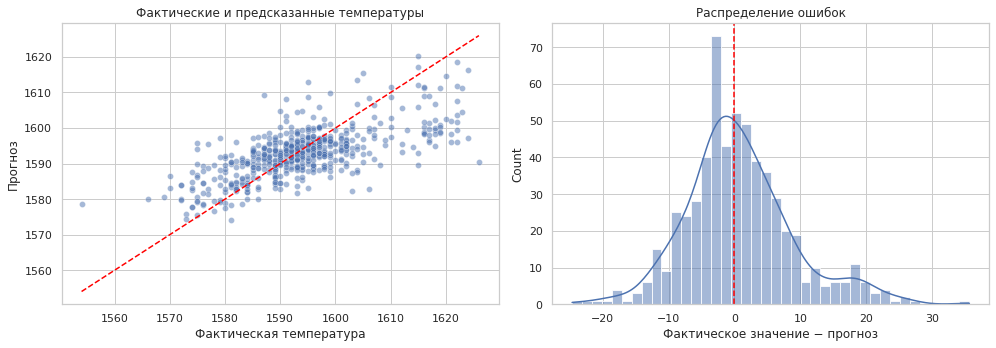

In [123]:
# Визуализация фактических и предсказанных температур

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=prediction_analysis,
    x='Фактическая температура',
    y='Прогноз',
    alpha=0.5,
    ax=axes[0]
)

temperature_min = min(
    prediction_analysis['Фактическая температура'].min(),
    prediction_analysis['Прогноз'].min()
)

temperature_max = max(
    prediction_analysis['Фактическая температура'].max(),
    prediction_analysis['Прогноз'].max()
)

axes[0].plot(
    [temperature_min, temperature_max],
    [temperature_min, temperature_max],
    color='red',
    linestyle='--'
)

axes[0].set_title('Фактические и предсказанные температуры')

sns.histplot(
    data=prediction_analysis,
    x='Ошибка',
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(
    0,
    color='red',
    linestyle='--'
)

axes[1].set_title('Распределение ошибок')
axes[1].set_xlabel('Фактическое значение − прогноз')

plt.tight_layout()
plt.show()

In [124]:
# Расчёт перестановочной важности признаков

permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='neg_mean_absolute_error',
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Признак': X_test.columns,
    'Рост MAE при перемешивании':
        permutation_result.importances_mean,
    'Стандартное отклонение':
        permutation_result.importances_std
}).sort_values(
    'Рост MAE при перемешивании',
    ascending=False
)

display(feature_importance)

,Признак,Рост MAE при перемешивании,Стандартное отклонение
0,Начальная_температура,2.156,0.142
2,Общая_длительность_нагрева,1.295,0.134
14,Bulk 6,0.301,0.044
24,Wire 2,0.179,0.044
10,Bulk 1,0.142,0.042
3,Средняя_длительность_нагрева,0.136,0.027
23,Wire 1,0.100,0.051
22,Интервал_подачи_сыпучих_сек,0.099,0.029
8,Общая_активная_энергия,0.096,0.040
19,Bulk 15,0.090,0.025


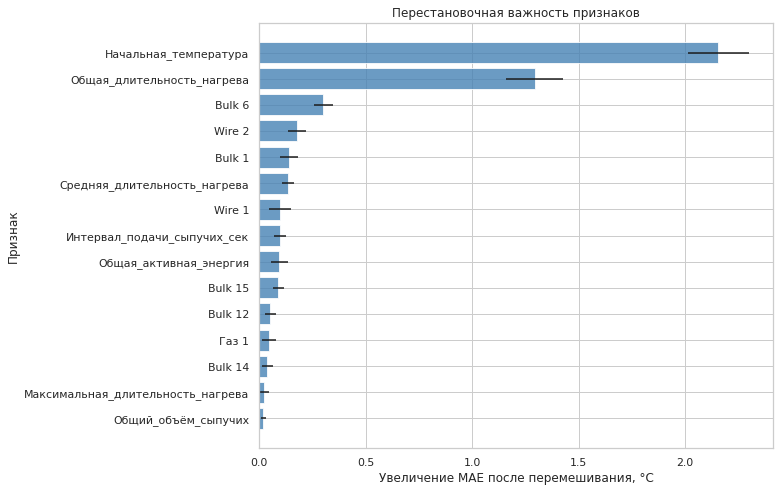

In [125]:
# Визуализация наиболее важных признаков

top_feature_importance = (
    feature_importance
    .head(15)
    .sort_values('Рост MAE при перемешивании')
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_feature_importance['Признак'],
    top_feature_importance['Рост MAE при перемешивании'],
    xerr=top_feature_importance['Стандартное отклонение'],
    color='steelblue',
    alpha=0.8
)

plt.axvline(0, color='black', linewidth=0.8)
plt.title('Перестановочная важность признаков')
plt.xlabel('Увеличение MAE после перемешивания, °C')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

### Анализ ошибок и важности признаков

Медианная абсолютная ошибка модели составила 4,426 °C. В 54,9% случаев
ошибка не превышала 5 °C, а в 81,4% — 10 °C. Средняя подписанная ошибка равна
0,741 °C, поэтому модель имеет небольшую тенденцию занижать конечную
температуру. На крайних значениях наблюдается стягивание прогнозов к среднему:
низкие температуры несколько завышаются, а высокие — занижаются.

Наиболее важным признаком оказалась начальная температура: её перемешивание
увеличивает MAE примерно на 4,1 °C. Далее следуют общая продолжительность
нагрева и общий объём проволочных материалов. Значимыми также оказались
`Bulk 6`, `Wire 1`, средняя продолжительность нагрева, активная энергия
и `Wire 2`.

Сопоставление важности с корреляционным анализом показало, что часть признаков
используется моделью нелинейно или во взаимодействии с другими параметрами.
Например, общий объём проволочных материалов имеет слабую монотонную
корреляцию с целью, но высокую перестановочную важность. Напротив, количество
типов проволочных материалов имеет заметную корреляцию, но небольшую
дополнительную важность после учёта объёмов отдельных материалов.

In [126]:
# Подготовка данных для исследования начальной температуры

initial_temperature_analysis = pd.DataFrame({
    'Начальная_температура':
        X_train['Начальная_температура'],
    'Конечная_температура':
        y_train
})

initial_temperature_analysis[
    'Диапазон_начальной_температуры'
] = pd.qcut(
    initial_temperature_analysis[
        'Начальная_температура'
    ],
    q=10,
    duplicates='drop'
)

initial_temperature_bins = (
    initial_temperature_analysis
    .groupby(
        'Диапазон_начальной_температуры',
        observed=True
    )
    .agg(
        Средняя_начальная_температура=(
            'Начальная_температура',
            'mean'
        ),
        Средняя_конечная_температура=(
            'Конечная_температура',
            'mean'
        ),
        Количество_партий=(
            'Конечная_температура',
            'size'
        )
    )
    .reset_index()
)

display(initial_temperature_bins)

,Диапазон_начальной_температуры,Средняя_начальная_температура,Средняя_конечная_температура,Количество_партий
0,"(1518.999, 1558.0]",1546.799,1586.728,184
1,"(1558.0, 1568.0]",1564.161,1589.337,193
2,"(1568.0, 1574.0]",1571.536,1592.137,168
3,"(1574.0, 1580.0]",1577.299,1593.280,157
4,"(1580.0, 1587.0]",1584.189,1592.806,196
5,"(1587.0, 1592.0]",1589.745,1593.229,153
6,"(1592.0, 1599.0]",1595.950,1593.916,179
7,"(1599.0, 1607.0]",1603.517,1596.878,172
8,"(1607.0, 1618.8]",1612.530,1596.066,166
9,"(1618.8, 1660.0]",1629.874,1598.737,175


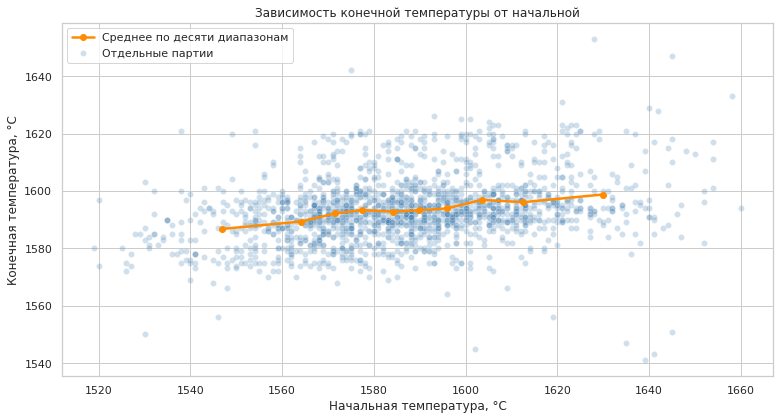

In [127]:
# Визуализация зависимости конечной температуры от начальной

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=initial_temperature_analysis,
    x='Начальная_температура',
    y='Конечная_температура',
    alpha=0.25,
    color='steelblue',
    label='Отдельные партии'
)

plt.plot(
    initial_temperature_bins[
        'Средняя_начальная_температура'
    ],
    initial_temperature_bins[
        'Средняя_конечная_температура'
    ],
    color='darkorange',
    marker='o',
    linewidth=2.5,
    label='Среднее по десяти диапазонам'
)

plt.title(
    'Зависимость конечной температуры от начальной'
)
plt.xlabel('Начальная температура, °C')
plt.ylabel('Конечная температура, °C')
plt.legend()
plt.tight_layout()
plt.show()

**Вывод.** Между начальной и конечной температурами наблюдается положительная, но нелинейная зависимость. При низкой начальной температуре сплав в среднем заметно нагревается, тогда как при высокой начальной температуре итоговое значение часто оказывается ниже исходного. Таким образом, технологический процесс стремится привести партии к целевому температурному диапазону. При этом значительный разброс конечной температуры внутри отдельных диапазонов подтверждает, что результат определяется не только начальной температурой, но и параметрами последующей обработки. Полученный результат согласуется с корреляционным анализом и высокой перестановочной важностью начальной температуры.

## Общий вывод

Целью проекта было построение модели, способной прогнозировать последнюю измеренную температуру сплава. Заказчик планирует применять модель для имитации технологического процесса и поиска способов сокращения энергопотребления на этапе обработки стали.

### Подготовка данных

Исходные данные были получены из базы SQLite и содержали информацию:

- о нагреве сплава электродами;
- продувке инертным газом;
- объёмах и времени подачи сыпучих материалов;
- объёмах и времени подачи проволочных материалов;
- измерениях температуры.

В процессе подготовки данных:

- типы числовых и временных признаков были приведены к корректному формату;
- проверены пропуски, дубликаты, бесконечные и аномальные значения;
- из таблицы нагрева исключена партия с отрицательной реактивной мощностью;
- исключены партии, содержащие температуру ниже установленного заказчиком порога 1500 °C;
- исключены партии, в которых было менее двух действительных измерений температуры;
- пропуски в данных о материалах были интерпретированы как отсутствие соответствующей добавки и заполнены нулями;
- наблюдения были агрегированы таким образом, чтобы каждой партии соответствовала одна строка;
- промежуточные измерения температуры не использовались в качестве признаков, поскольку это могло привести к утечке целевого признака.

В качестве целевого признака выбрана последняя измеренная температура партии, а первая измеренная температура использована как входной признак.

После объединения таблиц и окончательной подготовки выборка содержала **2468 партий и 31 входной признак**. Пропуски, бесконечные значения и дубликаты ключей в итоговой таблице отсутствовали.

### Исследовательский анализ

В ходе анализа были сформированы дополнительные технологически обоснованные признаки:

- количество и продолжительность нагревов;
- средняя и максимальная продолжительность одного нагрева;
- активная, реактивная и полная энергия;
- характеристики мощности;
- суммарные объёмы сыпучих и проволочных материалов;
- количество использованных типов материалов;
- интервалы между первой и последней подачей материалов.

Корреляционный анализ показал, что наиболее выраженная линейная связь с конечной температурой наблюдается у начальной температуры. При этом большинство признаков имеет умеренную или слабую индивидуальную связь с целевым признаком, поэтому их влияние может проявляться через нелинейные зависимости и взаимодействия.

Также были обнаружены группы практически дублирующих признаков мощности и энергии. Часть таких признаков была исключена для уменьшения избыточности данных. Дополнительно удалены постоянный признак и признаки материалов, встречающихся менее чем в 1% наблюдений.

Дополнительный анализ начальной температуры показал, что технологический процесс стремится привести партии к более узкому рабочему диапазону:

- партии с низкой начальной температурой в среднем заметно нагреваются;
- при средней начальной температуре изменение обычно невелико;
- при высокой начальной температуре итоговая температура нередко оказывается ниже исходной.

Следовательно, начальная температура задаёт исходное состояние сплава, однако итоговый результат также зависит от последующей обработки.

### Обучение моделей

Данные были разделены на обучающую и тестовую выборки в соотношении 75:25. Для сравнения моделей использовалась кросс-валидация с пятью блоками. Качество оценивалось метрикой MAE.

Константная модель `DummyRegressor` показала среднее MAE на кросс-валидации **9.801 °C**.

Были исследованы следующие модели:

- линейная модель с регуляризацией `Ridge`;
- нейронная сеть `MLPRegressor`;
- случайный лес `RandomForestRegressor`;
- градиентный бустинг `HistGradientBoostingRegressor`.

Наилучший результат после подбора гиперпараметров показал `HistGradientBoostingRegressor`:

- среднее MAE на кросс-валидации — **6.377 °C**;
- стандартное отклонение MAE — **0.300 °C**;
- MAE на обучающих блоках — **4.309 °C**.

Близость результатов разных валидационных блоков говорит о достаточной устойчивости модели. Итоговое качество было проверено на тестовой выборке только после завершения выбора модели и настройки гиперпараметров.

### Результаты на тестовой выборке

Итоговая модель показала:

- **MAE — 6.334 °C**;
- **R² — 0.703**.

Требование заказчика `MAE < 6.8 °C` выполнено.

Для сравнения, константная модель получила на тестовой выборке:

- MAE — **10.241 °C**;
- R² — **−0.019**.

Таким образом, итоговая модель снизила MAE относительно константного прогноза примерно на **3.9 °C**, или на **38%**.

Анализ ошибок показал:

- медианная абсолютная ошибка — **4.426 °C**;
- около **54.9%** прогнозов отличаются от фактической температуры не более чем на 5 °C;
- около **81.4%** прогнозов отличаются не более чем на 10 °C;
- средняя знаковая ошибка составляет **0.741 °C**, поэтому модель в среднем немного занижает температуру;
- максимальная абсолютная ошибка достигает **69.435 °C**.

На крайних значениях температуры заметен эффект стягивания прогноза к среднему: модель может завышать наиболее низкие и занижать наиболее высокие значения. Поэтому прогнозы для редких технологических режимов требуют дополнительного контроля.

### Важность признаков

По результатам перестановочной важности наибольший вклад в качество модели вносят:

1. начальная температура;
2. общая продолжительность нагрева;
3. общий объём проволочных материалов;
4. объём материала `Bulk 6`;
5. объём материала `Wire 1`;
6. средняя продолжительность нагрева;
7. общая активная энергия;
8. объём материала `Wire 2`;
9. максимальная продолжительность нагрева;
10. объём материала `Bulk 15`.

Результаты важности в целом согласуются с корреляционным анализом, но также показывают наличие нелинейных зависимостей. Например, общий объём проволочных материалов имеет сравнительно слабую монотонную связь с целевым признаком, однако оказывается одним из наиболее значимых признаков модели.

Перестановочная важность отражает вклад признаков в прогноз, но сама по себе не доказывает причинно-следственную связь. Поэтому изменять параметры технологического процесса только на основании важности признаков нельзя.

### Рекомендации заказчику

Разработанную модель можно использовать как часть системы имитации технологического процесса для оценки ожидаемой конечной температуры при различных сочетаниях параметров обработки.

Рекомендуется:

- применять модель в пределах диапазонов признаков, представленных в обучающих данных;
- использовать прогноз как инструмент поддержки специалиста, а не как полностью автономную систему управления;
- сравнивать сценарии с различной продолжительностью нагрева и объёмами добавляемых материалов, контролируя одновременно температурные и энергетические ограничения;
- уделять повышенное внимание прогнозам для редких режимов и крайних температур;
- контролировать качество датчиков температуры и мощности;
- сохранять фактические прогнозы и результаты процесса для мониторинга качества модели;
- отслеживать изменение распределений признаков и периодически переобучать модель на новых данных.

Для дальнейшего улучшения качества полезно добавить сведения о:

- химическом составе стали;
- марке и требуемых свойствах сплава;
- целевой температуре конкретной партии;
- состоянии ковша и его огнеупорной футеровки;
- характеристиках оборудования;
- последовательности технологических операций;
- температуре и химическом составе добавляемых материалов;
- простоях между операциями.

Особенно полезным будет накопление дополнительных наблюдений для редких и экстремальных температурных режимов. Это может уменьшить максимальные ошибки и ослабить склонность модели к прогнозированию значений, близких к среднему.

### Итог

Построенная модель градиентного бустинга успешно прогнозирует конечную температуру сплава и выполняет установленное заказчиком требование по MAE. Модель существенно превосходит константный прогноз и может быть использована как основа инструмента имитации процесса. При практическом внедрении необходимо учитывать границы применимости модели, контролировать качество входных данных и проводить технологические эксперименты перед изменением реального производственного режима.